# Project Thesis -Radar Based Gesture Recognition
## Sliding- Window Based Evaluation for Edge-AI

Student : Aman Syed
Matriculation No: 3401624
University: OTH Regensburg

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import os
import pandas as pd
import numpy as np
from scipy.signal import butter, sosfilt, sosfiltfilt
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_score, recall_score
from sklearn.model_selection import GroupShuffleSplit
from scipy.signal import stft
from scipy.signal import spectrogram


In [ ]:
# ============================================================
# METHOD TO LOAD SENSOR DATA
# ============================================================

def load_sensor_data(mode="60", gesture_dict=None, input_dir=None, pers=None, tot_gest=10, reps=10):
    """
    Loads sensor data for gesture recognition from a specified directory structure.
    Depending on the mode (either "60" for 60 GHz or "24" for 24 GHz), this function reads sensor data files,
    extracts gesture, repetition, and person information, and returns a concatenated pandas DataFrame with all data.
    
    Parameters:
        mode (str or int, optional): Frequency mode of the data. "60" or 60 for 60 GHz data (CSV files),
            "24" or 24 for 24 GHz data (TXT files). Default is "60".
        gesture_dict (dict, optional): Mapping from gesture indices to gesture names. If None, a default mapping is used.
        input_dir (str, optional): Directory containing the sensor data. If None, defaults to "data" + mode.
        pers (int, optional): Number of persons to load data for. If None, loads data for all persons.
        tot_gest (int, optional): Total number of gestures. Default is 10. (Unused in function logic.)
        reps (int, optional): Number of repetitions per gesture. Default is 10. (Unused in function logic.)
    
    Returns:
        pandas.DataFrame: Concatenated DataFrame containing all loaded sensor data, with columns for sensor readings,
            person name, person index, gesture, and repetition.
    
    Notes:
        - For 60 GHz data, expects CSV files with gesture and repetition encoded in the filename as "gesture__repetition".
        - For 24 GHz data, expects TXT files with gesture and repetition encoded in the filename, and uses a mapping
          to convert gesture codes to gesture names.
        - Adds columns: "Person_name", "Person", "Gesture", and "Repetition" to each loaded DataFrame.
        - Prints progress as persons are loaded.
    """
    # Simplified default parameters
    if gesture_dict is None:
        gesture_dict = {
            "0": "0_Valid_Kick",
            "1": "1_Valid_Kick_45",
            "2": "2_Valid_Kick_90",
            "3": "3_Valid_Kick_Sweep",
            "4": "4_Invalid_Washer",
            "5": "5_Invalid_Frontal_Walk",
            "6": "6_Invalid_Passing_By",
            "7": "7_Invalid_Trunk_Arrange",
            "8": "8_Invalid_Keys",
            "9": "9_Invalid_Object_Drop"
        }
    
    # Simplified: Use current input_dir if provided, else default
    if input_dir is None:
        input_dir = "data" + str(mode)
    
    data = []
    counter = 0
    
    # Simplified person folder iteration with early exit
    for person_folder in os.listdir(input_dir):
        # Skip folders starting with digits
        if person_folder[0].isdigit():
            continue
            
        person_name = person_folder
        person_path = os.path.join(input_dir, person_folder)
        
        # Simplified file processing loop
        for filename in os.listdir(person_path):
            file_path = os.path.join(person_path, filename)
            
            # Parse gesture and repetition from filename
            gesture = filename.split("__")[0]
            repetition = int(filename.split("__")[1])
            
            # Load sensor data
            sensor_df = pd.read_csv(file_path, delimiter=",", header=0, engine="python")
            
            # Set column names and convert to float32
            sensor_df.columns = ["I_data_lower", "Q_data_lower", "I_data_upper", "Q_data_upper"]
            sensor_df = sensor_df.astype("float32")
            
            # Add metadata columns
            sensor_df["Person_name"] = person_name
            sensor_df["Person"] = counter
            sensor_df["Gesture"] = gesture
            sensor_df["Repetition"] = repetition
            
            data.append(sensor_df)
        
        # Progress tracking
        counter += 1
        print(f"{counter}, ", end="")
        
        # Early exit if pers limit is reached
        if pers is not None and counter >= pers:
            break
    
    print("\n")
    # Concatenate all data into a single DataFrame
    df = pd.concat(data, ignore_index=True)
    return df

# Set RADAR_DATA_DIR before starting Python/Jupyter, or edit this path.
input_dir = os.path.expanduser(os.environ.get("RADAR_DATA_DIR", "data60"))
if not os.path.isdir(input_dir):
    raise FileNotFoundError(
        f"Radar dataset directory not found: {input_dir!r}. "
        "Set RADAR_DATA_DIR or update input_dir to your dataset folder."
    )

# Load data for first 10 persons
data = load_sensor_data(input_dir=input_dir, pers=10)
print(data.head())

1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 

   I_data_lower  Q_data_lower  I_data_upper  Q_data_upper  Person_name  \
0      0.662745      0.654902      0.662745      0.662745  ad_w_20_165   
1      0.658824      0.654902      0.662745      0.662745  ad_w_20_165   
2      0.662745      0.658824      0.662745      0.662745  ad_w_20_165   
3      0.662745      0.658824      0.662745      0.662745  ad_w_20_165   
4      0.658824      0.658824      0.658824      0.658824  ad_w_20_165   

   Person       Gesture  Repetition  
0       0  0_Valid_Kick           0  
1       0  0_Valid_Kick           0  
2       0  0_Valid_Kick           0  
3       0  0_Valid_Kick           0  
4       0  0_Valid_Kick           0  


In [ ]:
# ============================================================
# METHOD TO ADD COMBINATIONS AND LABELS
# ============================================================

def adding_combinatios_and_labels(df):
    """ArithmeticError
    Adds combination and labels to the DataFrame.
    Parameters:
        df (pd.DataFrame): DataFrame with sensor data.
    Returns:
        pd.DataFrame: DataFrame with added combinations and labels.
    """

    df["Combination"] = "p" + df["Person"].astype(str) + "-g" + df["Gesture"] + "-r" + df["Repetition"].astype(str)
    df["Binary_label"] = df["Gesture"].apply(lambda x: "Valid" if x[0] in ["0","1","2","3"] else "Invalid")
    df["Multiclass_label"] = df["Gesture"].astype(str)
    df = df.sort_values(by=["Person", "Gesture"])
    df = df.reset_index()
    df = df.drop("index", axis=1)
    df["Idx"] = df.groupby("Combination", sort = False).cumcount()
    return df
data = adding_combinatios_and_labels(data)
# Example usage
print("Data with combinations and labels added successfully.")
print(data.head())

Data with combinations and labels added successfully.
   I_data_lower  Q_data_lower  I_data_upper  Q_data_upper  Person_name  \
0      0.662745      0.654902      0.662745      0.662745  ad_w_20_165   
1      0.658824      0.654902      0.662745      0.662745  ad_w_20_165   
2      0.662745      0.658824      0.662745      0.662745  ad_w_20_165   
3      0.662745      0.658824      0.662745      0.662745  ad_w_20_165   
4      0.658824      0.658824      0.658824      0.658824  ad_w_20_165   

   Person       Gesture  Repetition          Combination Binary_label  \
0       0  0_Valid_Kick           0  p0-g0_Valid_Kick-r0        Valid   
1       0  0_Valid_Kick           0  p0-g0_Valid_Kick-r0        Valid   
2       0  0_Valid_Kick           0  p0-g0_Valid_Kick-r0        Valid   
3       0  0_Valid_Kick           0  p0-g0_Valid_Kick-r0        Valid   
4       0  0_Valid_Kick           0  p0-g0_Valid_Kick-r0        Valid   

  Multiclass_label  Idx  
0     0_Valid_Kick    0  
1     0_Va

In [ ]:
# ============================================================
# METHOD TO APPLY BANDPASS FILTER
# ============================================================

def butter_bandpass_sos(lowcut=50, highcut=1999, fs=4000, order=6):
    # Create bandpass filter coefficients
    return butter(order, [lowcut, highcut], fs=fs, btype='bandpass', output='sos')

def apply_bandpass(df, cols):
    # Create bandpass filter
    sos = butter_bandpass_sos(50, 1999, 4000, 6)
    out = df.copy()    
    # Apply filter to each column and add _bp suffix
    for c in cols:
        out[f"{c}_bp"] = sosfiltfilt(sos, df[c].values)
    return out

# Define I/Q data columns
iq_cols = ["I_data_lower", "Q_data_lower", "I_data_upper", "Q_data_upper"]
# Apply bandpass filter to all I/Q columns
filtered_df = apply_bandpass(data, iq_cols)
filtered_df.head()


,I_data_lower,Q_data_lower,I_data_upper,Q_data_upper,Person_name,Person,Gesture,Repetition,Combination,Binary_label,Multiclass_label,Idx,I_data_lower_bp,Q_data_lower_bp,I_data_upper_bp,Q_data_upper_bp
0,0.662745,0.654902,0.662745,0.662745,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,0_Valid_Kick,0,0.000093,-0.000105,0.000022,0.000070
1,0.658824,0.654902,0.662745,0.662745,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,0_Valid_Kick,1,-0.003714,-0.000307,0.000238,0.000201
2,0.662745,0.658824,0.662745,0.662745,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,0_Valid_Kick,2,0.000328,0.003554,0.000216,0.000267
3,0.662745,0.658824,0.662745,0.662745,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,0_Valid_Kick,3,0.000440,0.003355,0.000432,0.000397
4,0.658824,0.658824,0.658824,0.658824,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,0_Valid_Kick,4,-0.003363,0.003298,-0.003513,-0.003461


In [ ]:
# ============================================================
# METHOD TO NORMALIZE COLUMNS
# ============================================================

def normalize_columns(df, cols):
    """
    NORMALIZATION TO [-1, 1]
    Normalizes selected columns using global min/max values:
        x_norm = 2*(x - min) / (max - min) - 1
    WHY THIS STEP IS IMPORTANT:
    - Radar signals may have different amplitude ranges across sessions/persons.
    - Normalizing to [-1,1] stabilizes neural network training.
    - Columns are normalized consistently across all samples.
    """

    out = df.copy()

    # Compute global min/max across all selected columns
    min_val = out[cols].min().min()
    max_val = out[cols].max().max()

    # Apply normalization
    for c in cols:
        out[f"{c}_norm"] = 2 * (out[c] - min_val) / (max_val - min_val) - 1

    return out

bp_cols = [f"{c}_bp" for c in iq_cols]   # ["I_data_lower_bp", ..., "Q_data_upper_bp"]

normalized_df = normalize_columns(filtered_df, bp_cols)
norm_cols = [f"{c}_bp_norm" for c in iq_cols]
print(normalized_df[norm_cols].min().min(), normalized_df[norm_cols].max().max())


# Quick check — normalized values should be in [-1, +1]
print(normalized_df[["I_data_upper_bp_norm", "Q_data_upper_bp_norm"]].describe())

-1.0 1.0
       I_data_upper_bp_norm  Q_data_upper_bp_norm
count          1.200000e+07          1.200000e+07
mean           6.141191e-02          6.141191e-02
std            3.495959e-02          3.636309e-02
min           -9.382058e-01         -1.000000e+00
25%            5.782195e-02          5.777902e-02
50%            6.119656e-02          6.118674e-02
75%            6.524357e-02          6.527339e-02
max            1.000000e+00          9.436195e-01


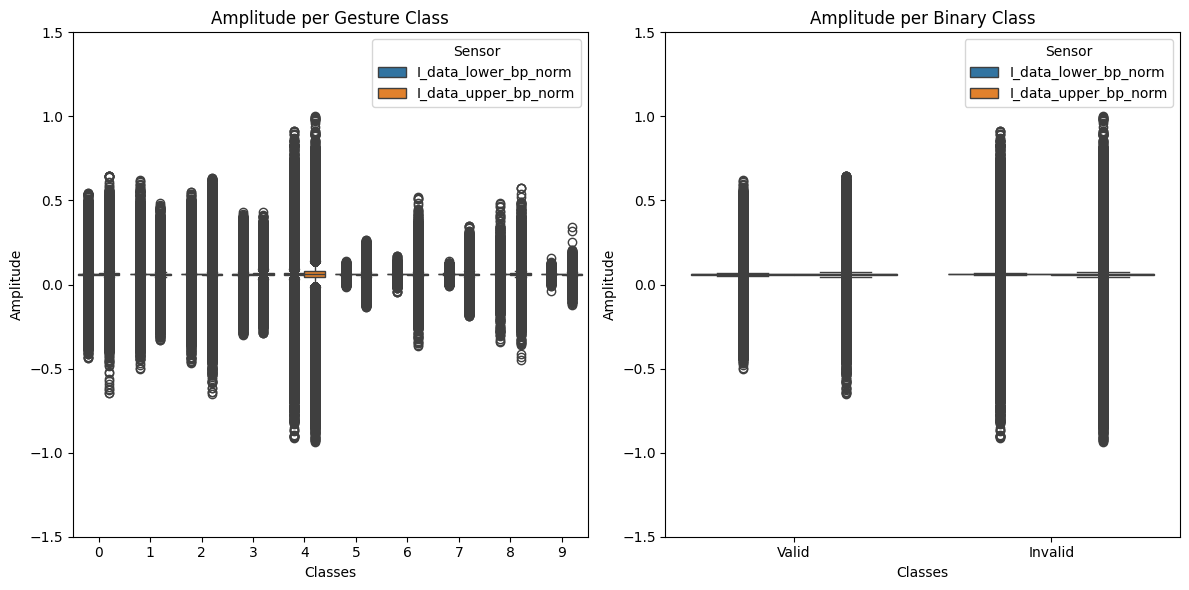

In [ ]:
# ============================================================
# PLOTTING METHOD - BOXPLOT BY CLASS WITH FULL RANGE
# ============================================================

def plot_boxplot_by_class_with_full_range(df, sensor_cols=None):
    """
    Plots boxplots for each sensor column by gesture and binary class,
    showing the full range of data.
    """
    # Define default sensor columns if not provided
    if sensor_cols is None:
        sensor_cols = ['I_data_lower_bp_norm', 'I_data_upper_bp_norm']

    # Ensure the correct column names are used
    df_long = pd.melt(df, id_vars=["Gesture", "Binary_label"], value_vars=sensor_cols, var_name="Sensor", value_name="Amplitude")

    # Reduce the size of the data to avoid memory issues

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Left Plot: Gesture Class
    sns.boxplot(data=df_long, x="Gesture", y="Amplitude", hue="Sensor", showfliers=True, ax=axes[0])
    axes[0].set_title("Amplitude per Gesture Class")
    axes[0].set_xlabel("Classes")
    axes[0].set_ylabel("Amplitude")
    axes[0].set_ylim(-1.5, 1.5)
    axes[0].set_xticks(range(10))
    axes[0].set_xticklabels(range(10))

    # Right Plot: Binary Class
    sns.boxplot(data=df_long, x="Binary_label", y="Amplitude", hue="Sensor", showfliers=True, ax=axes[1])
    axes[1].set_title("Amplitude per Binary Class")
    axes[1].set_xlabel("Classes")
    axes[1].set_ylabel("Amplitude")
    axes[1].set_ylim(-1.5, 1.5)
    axes[1].legend(title="Sensor")
    plt.tight_layout()
    plt.show()

df = data.copy()

# Call the function with reduced data
plot_boxplot_by_class_with_full_range(normalized_df)


In [ ]:
# ============================================================
# METHOD TO EXTRACT WINDOW AROUND PEAK ENVELOPE
# ============================================================

def ensure_envelope(df, I_col="I_data_upper_bp_norm", Q_col="Q_data_upper_bp_norm"):
    out = df.copy()
    if "Envelope" not in out.columns:
        out["Envelope"] = np.sqrt(out[I_col].to_numpy()**2 + out[Q_col].to_numpy()**2)
    return out

# Apply envelope calculation
enveloped_df = ensure_envelope(normalized_df)
def extract_window(df, window_s=1.0, fs=4000):
    idx_peak = df["Envelope"].idxmax()
    half = int(window_s * fs / 2)
    start = max(idx_peak - half, 0)
    end   = min(idx_peak + half, len(df)-1)
    return df.loc[start:end].reset_index(drop=True)

# Pick any gesture instance (e.g. first)
comb = enveloped_df["Combination"].unique()[0]
ex = enveloped_df[enveloped_df["Combination"]==comb].reset_index(drop=True)
window_df = extract_window(ex)
window_df.head(5)


,I_data_lower,Q_data_lower,I_data_upper,Q_data_upper,Person_name,Person,Gesture,Repetition,Combination,Binary_label,...,Idx,I_data_lower_bp,Q_data_lower_bp,I_data_upper_bp,Q_data_upper_bp,I_data_lower_bp_norm,Q_data_lower_bp_norm,I_data_upper_bp_norm,Q_data_upper_bp_norm,Envelope
0,0.666667,0.654902,0.662745,0.654902,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,...,4809,0.006038,-0.001898,0.000625,-0.003291,0.070551,0.058539,0.062358,0.056430,0.084100
1,0.666667,0.658824,0.662745,0.650980,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,...,4810,0.006025,0.002021,0.000699,-0.007131,0.070531,0.064471,0.062470,0.050618,0.080403
2,0.666667,0.658824,0.666667,0.654902,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,...,4811,0.006041,0.001998,0.004553,-0.003176,0.070555,0.064436,0.068304,0.056605,0.088710
3,0.662745,0.658824,0.662745,0.650980,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,...,4812,0.002107,0.001996,0.000702,-0.007013,0.064600,0.064432,0.062475,0.050796,0.080519
4,0.662745,0.658824,0.670588,0.654902,ad_w_20_165,0,0_Valid_Kick,0,p0-g0_Valid_Kick-r0,Valid,...,4813,0.002123,0.001972,0.008475,-0.003057,0.064626,0.064397,0.074240,0.056785,0.093467



=== Gesture: 0_Valid_Kick ===


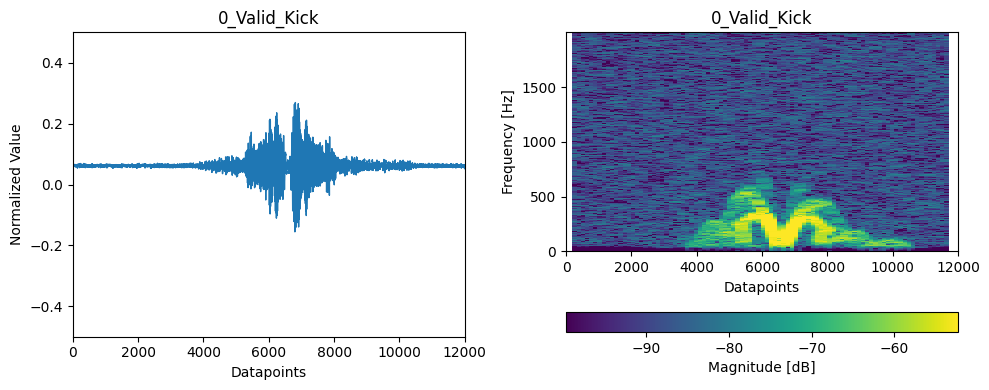


=== Gesture: 1_Valid_Kick_45 ===


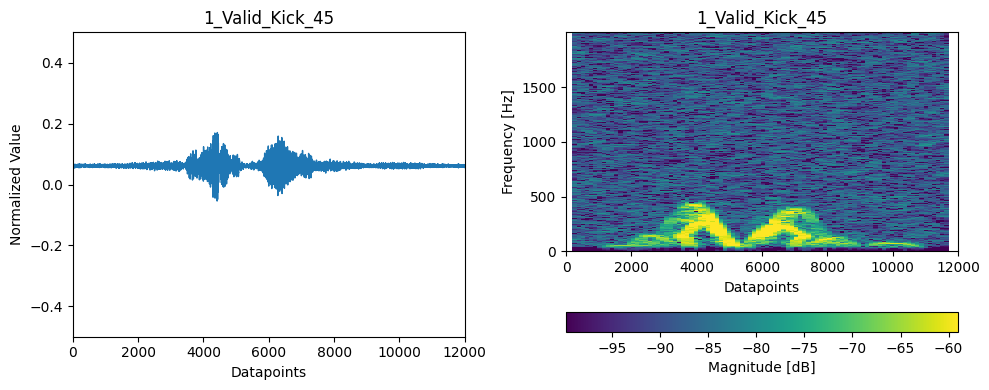


=== Gesture: 2_Valid_Kick_90 ===


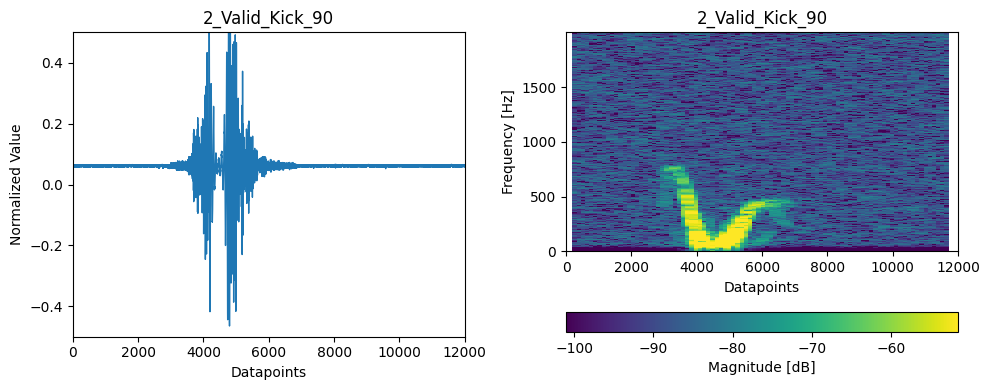


=== Gesture: 3_Valid_Kick_Sweep ===


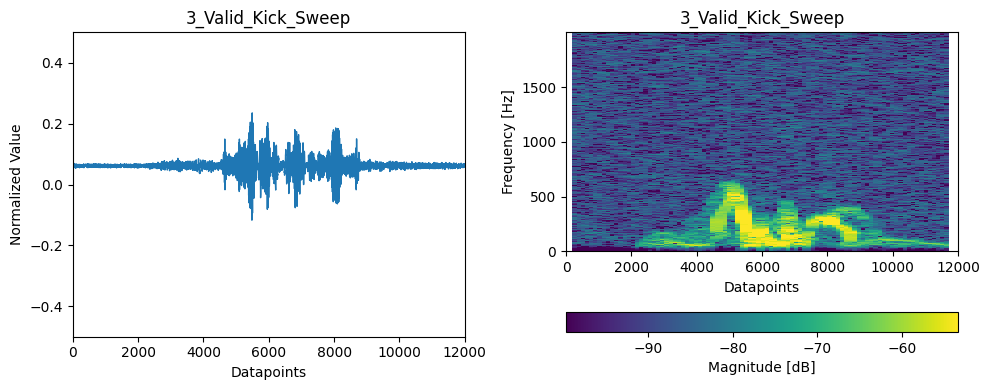


=== Gesture: 4_Invalid_Washer ===


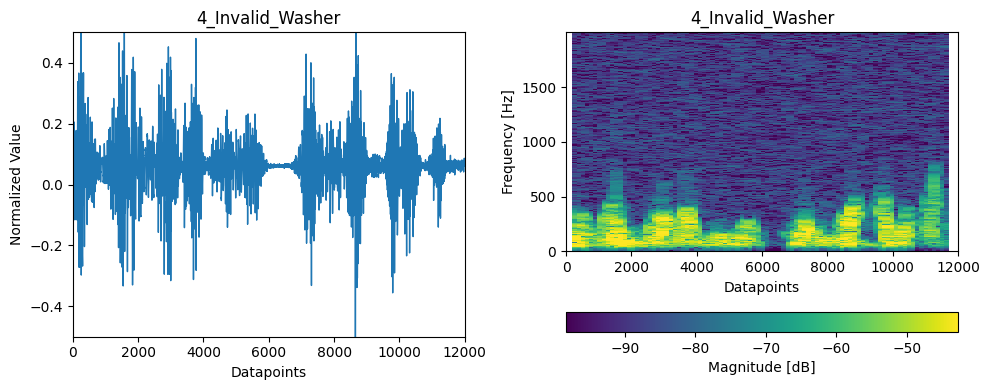


=== Gesture: 5_Invalid_Frontal_Walk ===


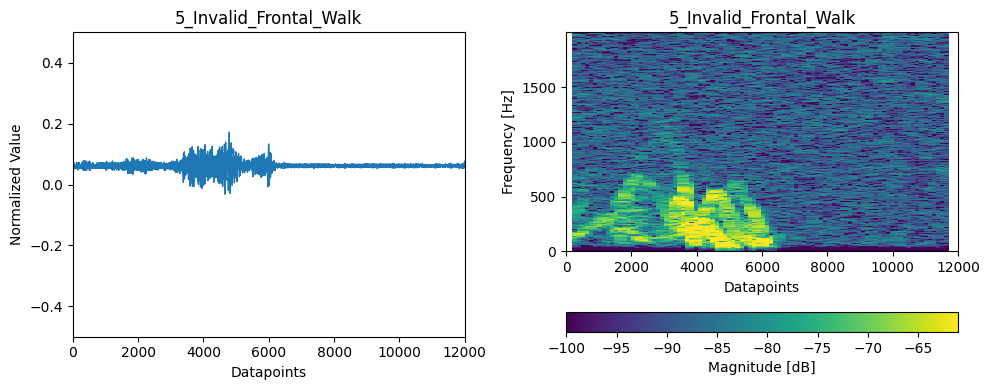


=== Gesture: 6_Invalid_Passing_By ===


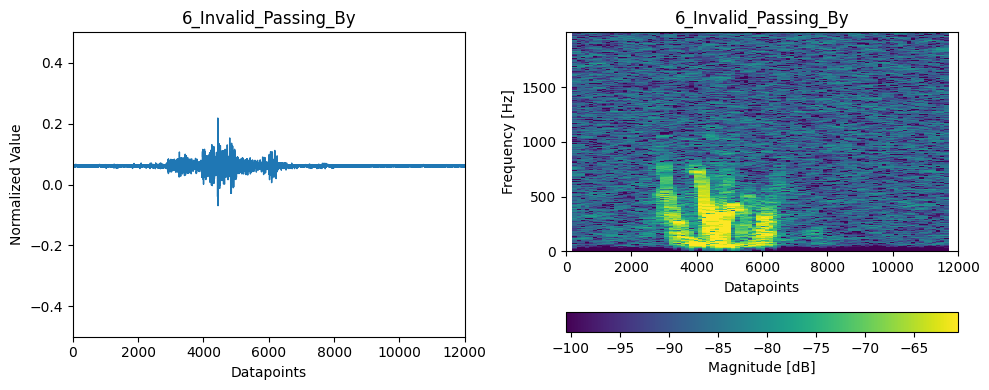


=== Gesture: 7_Invalid_Trunk_Arrange ===


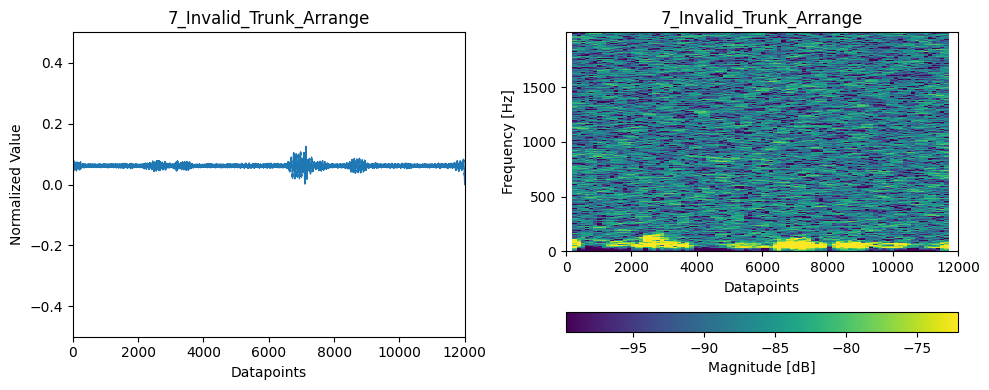


=== Gesture: 8_Invalid_Keys ===


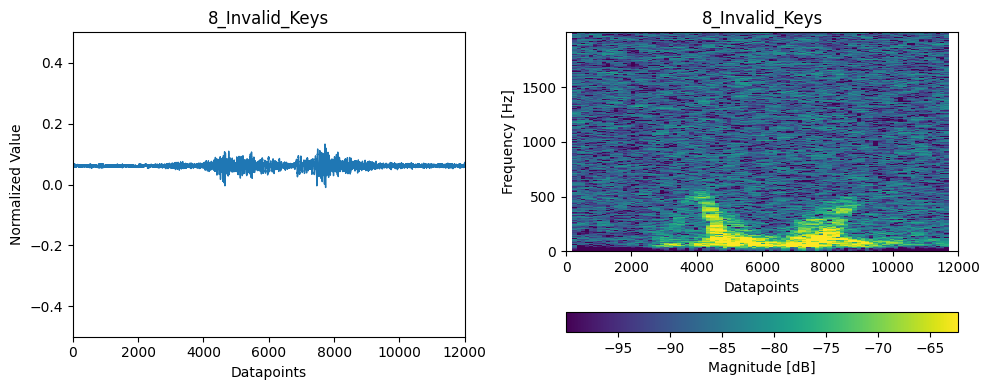


=== Gesture: 9_Invalid_Object_Drop ===


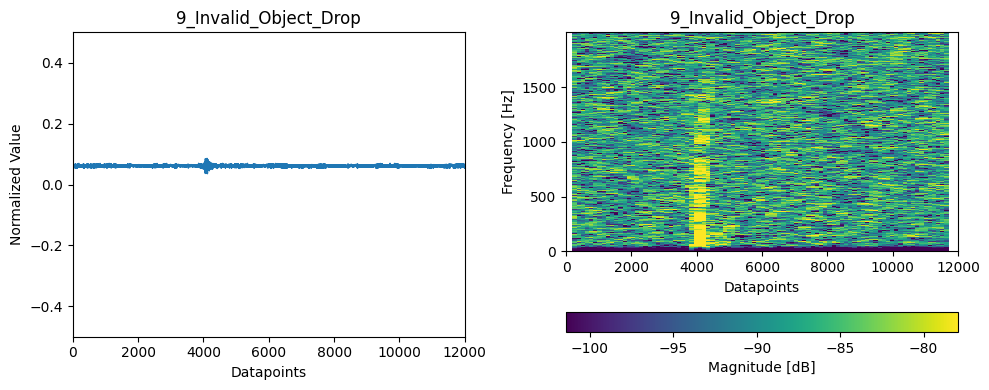

In [ ]:
# ============================================================
# PLOTTING METHOD - WAVEFORM AND SPECTROGRAM
# ============================================================

def plot_wave_and_spectrogram(df_segment, signal_col="I_data_upper_bp_norm",
                              fs=4000, x_max=12000, fmax=1999,
                              y_lim=(-0.5, 0.5), title_prefix=""):
    y = df_segment[signal_col].to_numpy(dtype=np.float32)
    t = np.arange(len(y))
    #plot in single figure Waveform (normalized value vs datapoints) and Spectrogram (x in samples; y in Hz; color = dB)
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(t, y, lw=1, label="I_upper")
    plt.xlim(0, x_max); plt.ylim(*y_lim)
    plt.xlabel("Datapoints"); plt.ylabel("Normalized Value")
    comb = df_segment["Combination"].iloc[0] if "Combination" in df_segment.columns else ""
    plt.title(f"{title_prefix}{df_segment['Gesture'].iloc[0]}")
    plt.subplot(1, 2, 2)
    x = y - np.mean(y)
    f, tt, Sxx = spectrogram(x, fs=fs, nperseg=512, noverlap=384, scaling="density", mode="magnitude")
    m = f <= fmax; f = f[m]; Sxx = Sxx[m, :]
    Sxx_db = 20 * np.log10(np.maximum(Sxx, 1e-12))
    x_samples = tt * fs
    # 🔵 Use viridis colormap and FIX dB range to [-80, -20]
    vmin = np.percentile(Sxx_db, 5)
    vmax = np.percentile(Sxx_db, 99)
    im = plt.pcolormesh(x_samples, f, Sxx_db, shading='nearest',cmap="viridis", vmin=-80, vmax=-20)
    im.set_clim(vmin, vmax)
    plt.xlim(0, x_max); plt.ylim(0, fmax)
    plt.xlabel("Datapoints"); plt.ylabel("Frequency [Hz]")
    plt.title(f"{title_prefix}{df_segment['Gesture'].iloc[0]}")
    cbar = plt.colorbar(orientation="horizontal", pad=0.2, fraction=0.08)
    cbar.set_label("Magnitude [dB]")
    plt.tight_layout()
    plt.show()


# ---- LOOP: one example per gesture (first available Combination) ----
# all gestures with single example per gesture will be plotted in a single figure with subplots for each gesture in order

for g, gdf in enveloped_df.groupby("Gesture", sort=False):
    comb = gdf["Combination"].iloc[0]                      # pick first trial for this gesture
    block = enveloped_df[enveloped_df["Combination"] == comb].reset_index(drop=True)
    win = extract_window(block, window_s=1.0, fs=4000)     # 1 s around envelope peak

    print(f"\n=== Gesture: {g} ===")
    # full 3 s (0..12000 samples)
    plot_wave_and_spectrogram(block, signal_col="I_data_upper_bp_norm",
                              fs=4000, x_max=12000, fmax=1999, y_lim=(-0.5, 0.5))


=== METHOD 1 | WINDOW = 4000 ===


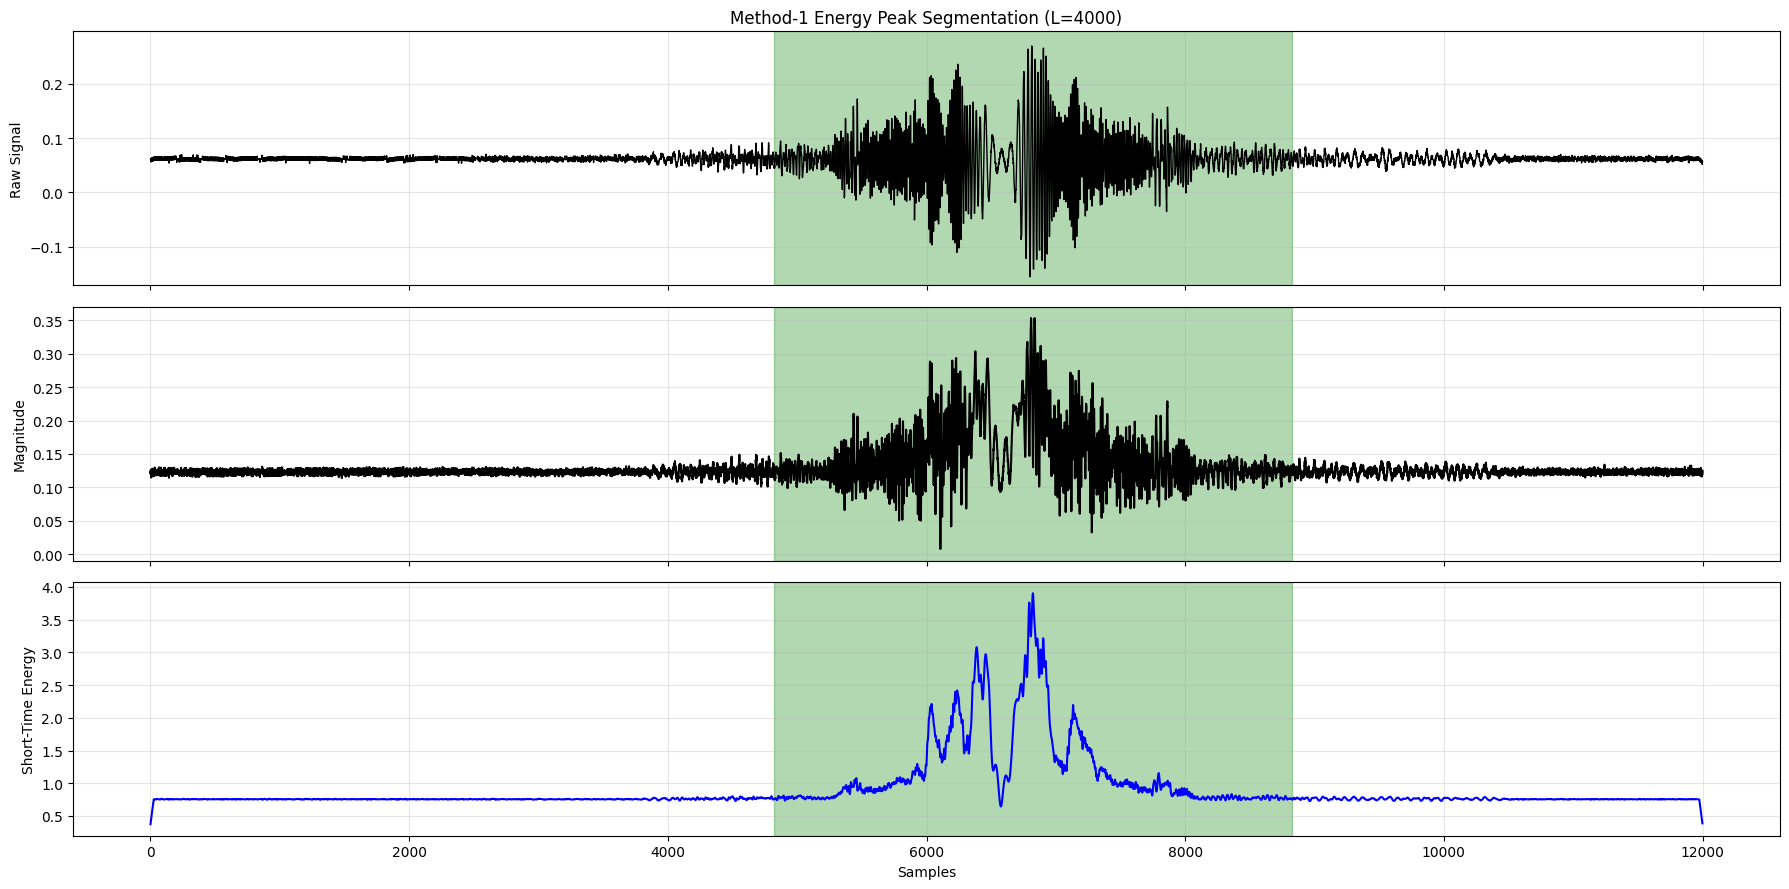

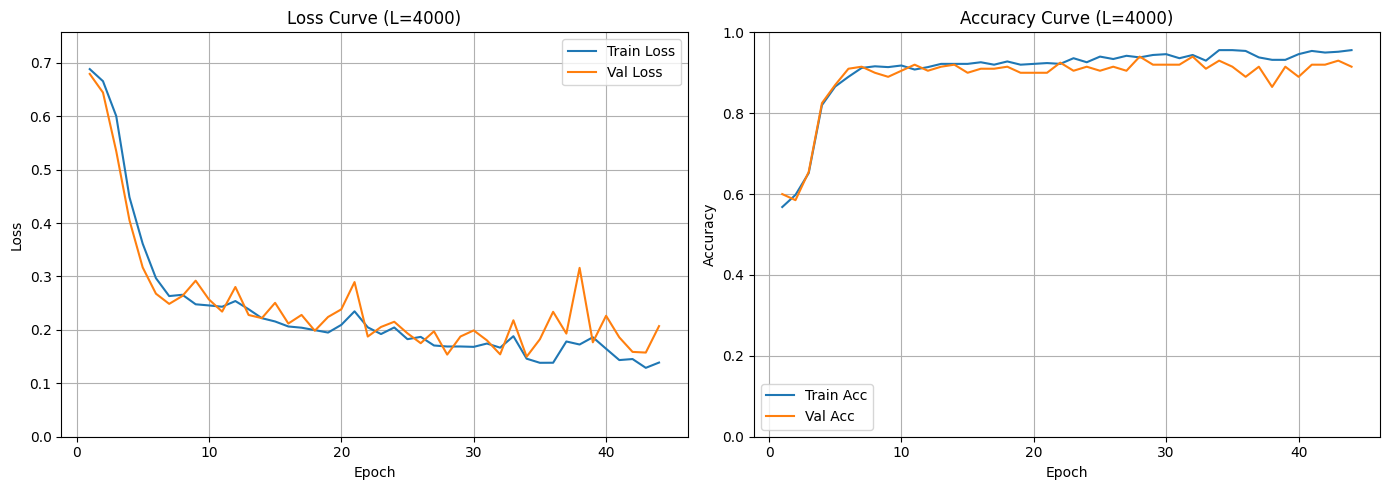

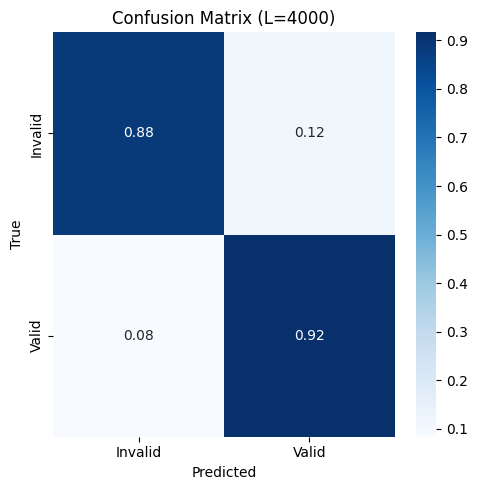

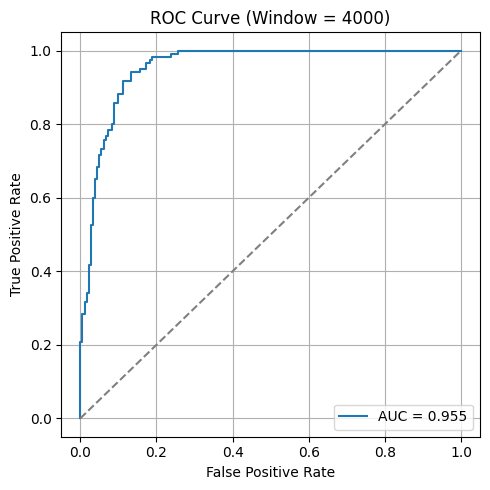


=== METHOD 1 | WINDOW = 2000 ===


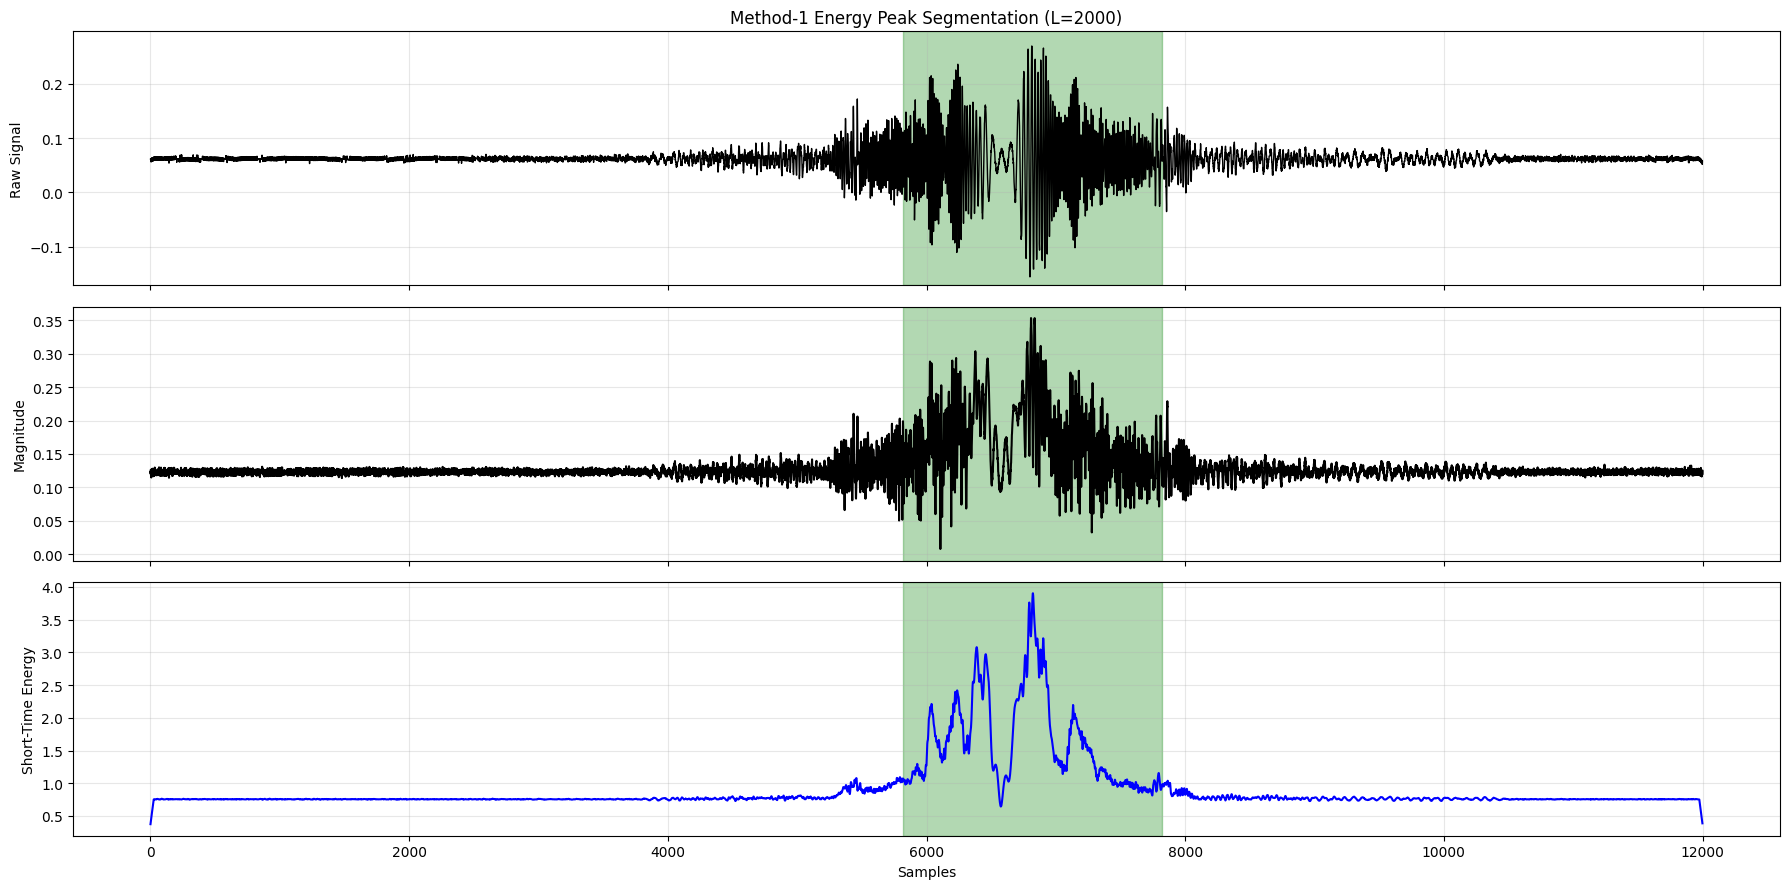

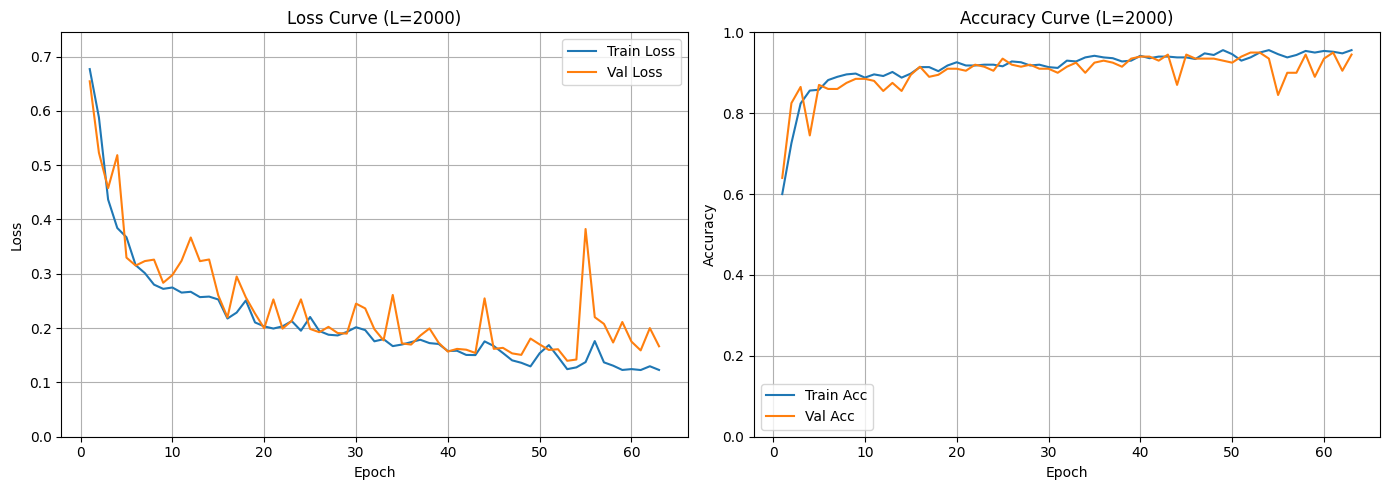

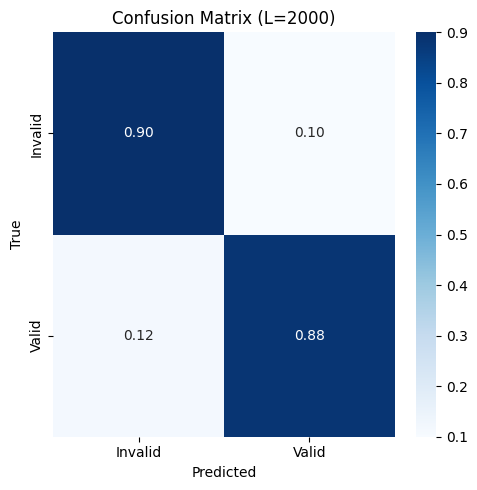

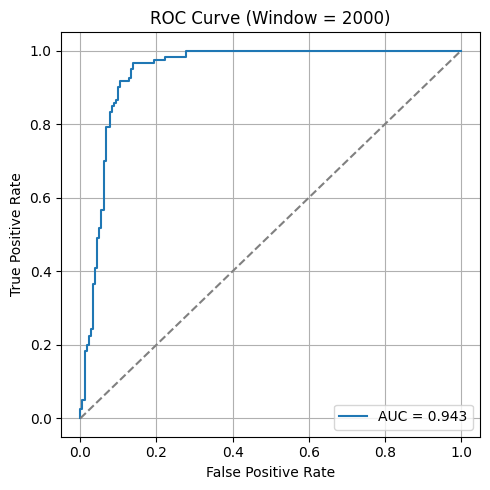


=== METHOD 1 | WINDOW = 1000 ===


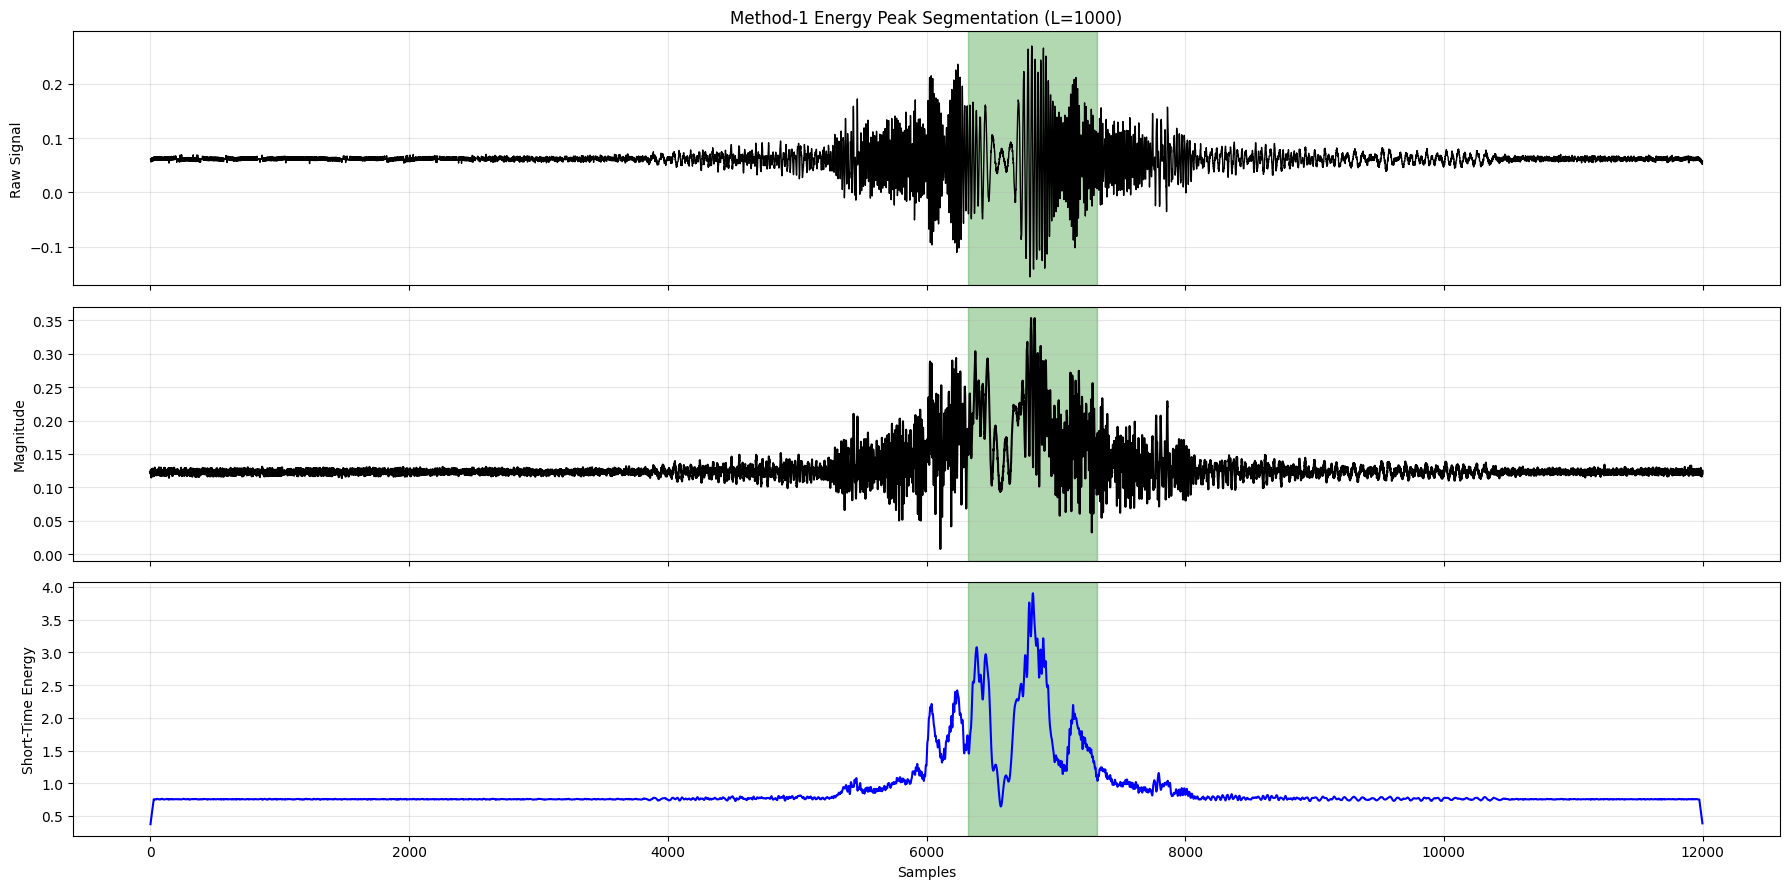

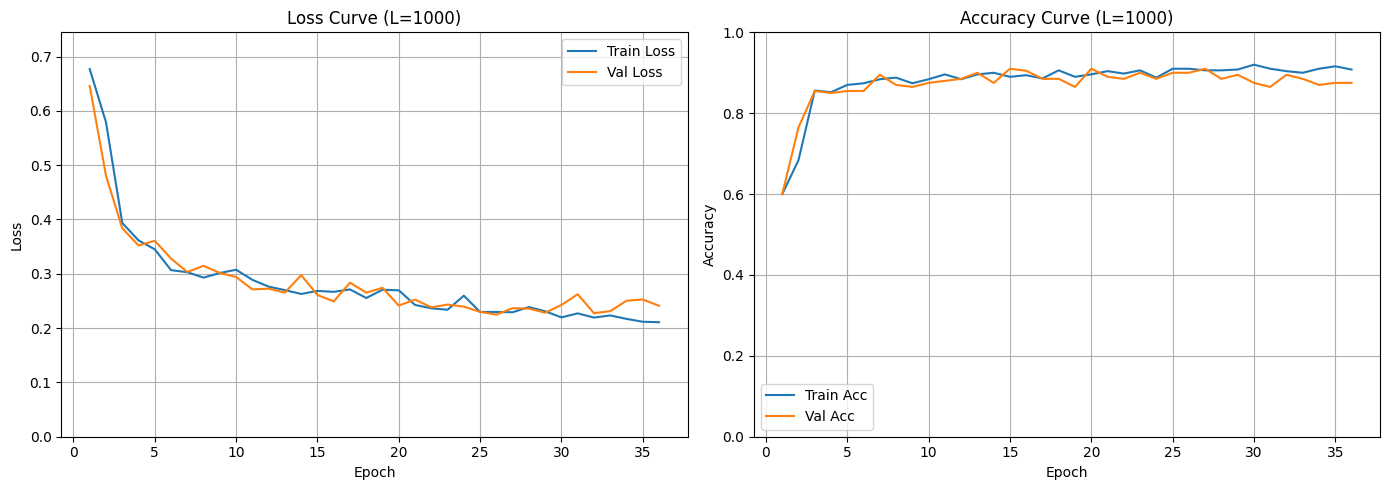

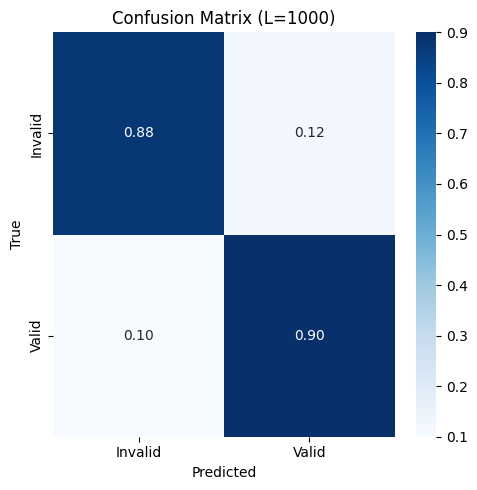

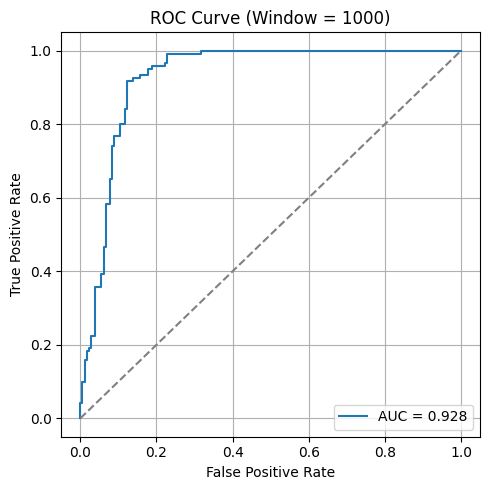


=== METHOD-1 FINAL TABLE [ENERGY PEAK SEGMENTATION ] ===


,Window,ACC,Precision,Recall_TPR,FPR,AUC
0,4000,0.8967,0.8397,0.9167,0.1167,0.9548
1,2000,0.8933,0.8548,0.8833,0.1000,0.9432
2,1000,0.8867,0.8308,0.9000,0.1222,0.9283


In [ ]:
# ============================================================
# METHOD 1 – ENERGY PEAK SEGMENTATION 
# ============================================================
# CONFIGURATION

WINDOWS = [4000, 2000, 1000]
TEST_PERSONS = [2, 5, 8, 11, 14, 17, 20, 23, 26, 29]  # fixed 20%
NORM_COLS = [
    "I_data_lower_bp_norm",
    "Q_data_lower_bp_norm",
    "I_data_upper_bp_norm",
    "Q_data_upper_bp_norm",
]

MAX_EPOCHS = 100        
BATCH_SIZE = 32
PATIENCE = 10           

# ------------------------------------------------------------
# CNN MODEL 
# ------------------------------------------------------------
def make_cnn(L):
    inp = layers.Input(shape=(L, 4))

    x = layers.Conv1D(32, 7, padding="same", activation="relu")(inp)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dense(64, activation="relu")(x)

    out = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inp, out)
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

def extract_12000_window(X, target_len=12000):
    """
    Enforces a fixed 12000-sample parent window.
    If signal is longer → center crop
    If shorter → discard
    """
    if len(X) < target_len:
        return None

    start = (len(X) - target_len) // 2
    end = start + target_len
    return X[start:end]

# ------------------------------------------------------------
# ENERGY PEAK SEGMENTATION
# ------------------------------------------------------------
def segment_energy_peak(X, L, frame=50):
    mag = np.sqrt(np.sum(X**2, axis=1))
    energy = np.convolve(mag**2, np.ones(frame), mode="same")

    peak = np.argmax(energy)
    start = max(0, peak - L//2)
    end = start + L
    if end > len(X):
        end = len(X)
        start = end - L

    return X[start:end]
# ------------------------------------------------------------
# SLIDING WINDOW EVALUATION (TEST ONLY)
# ------------------------------------------------------------
def sliding_window_predict(model, X_12000, L, step=500):
    """
    Sliding-window prediction over unseen test samples.
    Returns mean probability across windows.
    """
    probs = []

    for start in range(0, len(X_12000) - L + 1, step):
        window = X_12000[start:start + L]
        window = window[np.newaxis, ...]
        probs.append(model.predict(window, verbose=0)[0, 0])

    return np.mean(probs)

# ------------------------------------------------------------
# DATASET BUILDER (SEGMENT LEVEL)
# ------------------------------------------------------------
def build_dataset(df, L):
    Xs, ys, persons = [], [], []

    le = LabelEncoder()
    le.fit(df.groupby("Combination")["Binary_label"].first())

    for _, g in df.groupby("Combination"):
        X_full = g[NORM_COLS].values
        X_12000 = extract_12000_window(X_full) 

        if X_12000 is None:
            continue

        y = le.transform([g["Binary_label"].iloc[0]])[0]
        p = g["Person"].iloc[0]

        seg = segment_energy_peak(X_12000, L)    # segmentation INSIDE 12000
        if seg.shape[0] == L:
            Xs.append(seg)
            ys.append(y)
            persons.append(p)

    return np.array(Xs), np.array(ys), np.array(persons)

# ------------------------------------------------------------
# TRAINING CURVE PLOT
# ------------------------------------------------------------
def plot_training_curves(history, L):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)

    plt.figure(figsize=(14,5))

    # LOSS
    plt.subplot(1,2,1)
    plt.plot(epochs, h["loss"], label="Train Loss")
    plt.plot(epochs, h["val_loss"], label="Val Loss")
    plt.ylim(0, max(h["loss"] + h["val_loss"]) * 1.1)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Loss Curve (L={L})")
    plt.grid(True)
    plt.legend()

    # ACCURACY
    plt.subplot(1,2,2)
    plt.plot(epochs, h["accuracy"], label="Train Acc")
    plt.plot(epochs, h["val_accuracy"], label="Val Acc")
    plt.ylim(0, 1.0)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy Curve (L={L})")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# METHOD-1 VISUALIZATION 
# ------------------------------------------------------------
def plot_method1_visualization(df, L, example_idx=0, frame=50):
    """
    Method-1 visualization showing :
    1) Raw signal
    2) Magnitude
    3) Short-time energy
    """

    # Pick one example
    combo = df["Combination"].unique()[example_idx]
    g = df[df["Combination"] == combo]

    raw = g["I_data_upper_bp_norm"].values
    X_full = g[NORM_COLS].values

    # Energy segmentation
    mag = np.sqrt(np.sum(X_full**2, axis=1))
    energy = np.convolve(mag**2, np.ones(frame), mode="same")

    peak = np.argmax(energy)
    start = max(0, peak - L // 2)
    end = start + L
    if end > len(raw):
        end = len(raw)
        start = end - L

    fig, ax = plt.subplots(3, 1, figsize=(18, 9), sharex=True)

    # --------------------------------------------------
    # Raw signal (positive + negative)
    # --------------------------------------------------
    ax[0].plot(raw, color="black", linewidth=1)
    ax[0].axvspan(start, end, color="green", alpha=0.3)
    ax[0].set_ylabel("Raw Signal")
    ax[0].set_title(f"Method-1 Energy Peak Segmentation (L={L})")
    ax[0].grid(True, alpha=0.3)
    ax[0].set_ylim(raw.min()*1.1, raw.max()*1.1)

    # --------------------------------------------------
    # Magnitude
    # --------------------------------------------------
    ax[1].plot(mag, color="black")
    ax[1].axvspan(start, end, color="green", alpha=0.3)
    ax[1].set_ylabel("Magnitude")
    ax[1].grid(True, alpha=0.3)

    # --------------------------------------------------
    # Short-time energy (decision signal)
    # --------------------------------------------------
    ax[2].plot(energy, color="blue")
    ax[2].axvspan(start, end, color="green", alpha=0.3)
    ax[2].set_ylabel("Short-Time Energy")
    ax[2].set_xlabel("Samples")
    ax[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# ROC CURVE (Plot)
# ------------------------------------------------------------
def plot_roc_curve(y_test, y_prob, window_size):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = auc(fpr, tpr)

    plt.figure(figsize=(5, 5))
    plt.plot(fpr, tpr, label=f'AUC = {auc_value:.3f}')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'ROC Curve (Window = {window_size})')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# MAIN PIPELINE
# ------------------------------------------------------------
results = []

for L in WINDOWS:
    print(f"\n=== METHOD 1 | WINDOW = {L} ===")

    # Build dataset
    X, y, persons = build_dataset(normalized_df, L)
    plot_method1_visualization(normalized_df, L, example_idx=0, frame=50)

    # Fixed person-wise split
    test_mask = np.isin(persons, TEST_PERSONS)
    X_trainval, y_trainval = X[~test_mask], y[~test_mask]
    X_test, y_test = X[test_mask], y[test_mask]
    persons_trainval = persons[~test_mask]

    # Inner split for validation
    gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    tr_idx, val_idx = next(gss.split(X_trainval, y_trainval, groups=persons_trainval))

    X_tr, X_val = X_trainval[tr_idx], X_trainval[val_idx]
    y_tr, y_val = y_trainval[tr_idx], y_trainval[val_idx]

    # Model
    model = make_cnn(L)

    es = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[es],
        verbose=0
    )

    # Plot curves
    plot_training_curves(history, L)

    # ------------------------------------------------------------
    # SLIDING-WINDOW TEST EVALUATION (UNSEEN PERSONS)
    # ------------------------------------------------------------
    y_prob, y_pred = [], []

    for i in range(len(X_test)):
        prob = sliding_window_predict(model, X_test[i], L)
        y_prob.append(prob)
        y_pred.append(int(prob >= 0.5))

    y_prob = np.array(y_prob)
    y_pred = np.array(y_pred)


    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    ACC = (tp + tn) / (tp + tn + fp + fn)
    PREC = precision_score(y_test, y_pred)
    TPR = recall_score(y_test, y_pred)
    FPR = fp / (fp + tn)
    AUC = auc(*roc_curve(y_test, y_prob)[:2])

    # Confusion matrix 
    cm = confusion_matrix(y_test, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(5,5))
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=["Invalid","Valid"],
                yticklabels=["Invalid","Valid"])
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix (L={L})")
    plt.tight_layout()
    plt.show()
    # ROC curve 
    plot_roc_curve(y_test, y_prob, L)
    
    results.append({
        "Window": L,
        "ACC": ACC,
        "Precision": PREC,
        "Recall_TPR": TPR,
        "FPR": FPR,
        "AUC": AUC
     })

# ------------------------------------------------------------
# FINAL COMPARISON TABLE
# ------------------------------------------------------------
m1_table = pd.DataFrame(results).sort_values("Window", ascending=False)

print("\n=== METHOD-1 FINAL TABLE [ENERGY PEAK SEGMENTATION ] ===")
display(m1_table.round(4))



=== METHOD 2 | WINDOW = 4000 ===


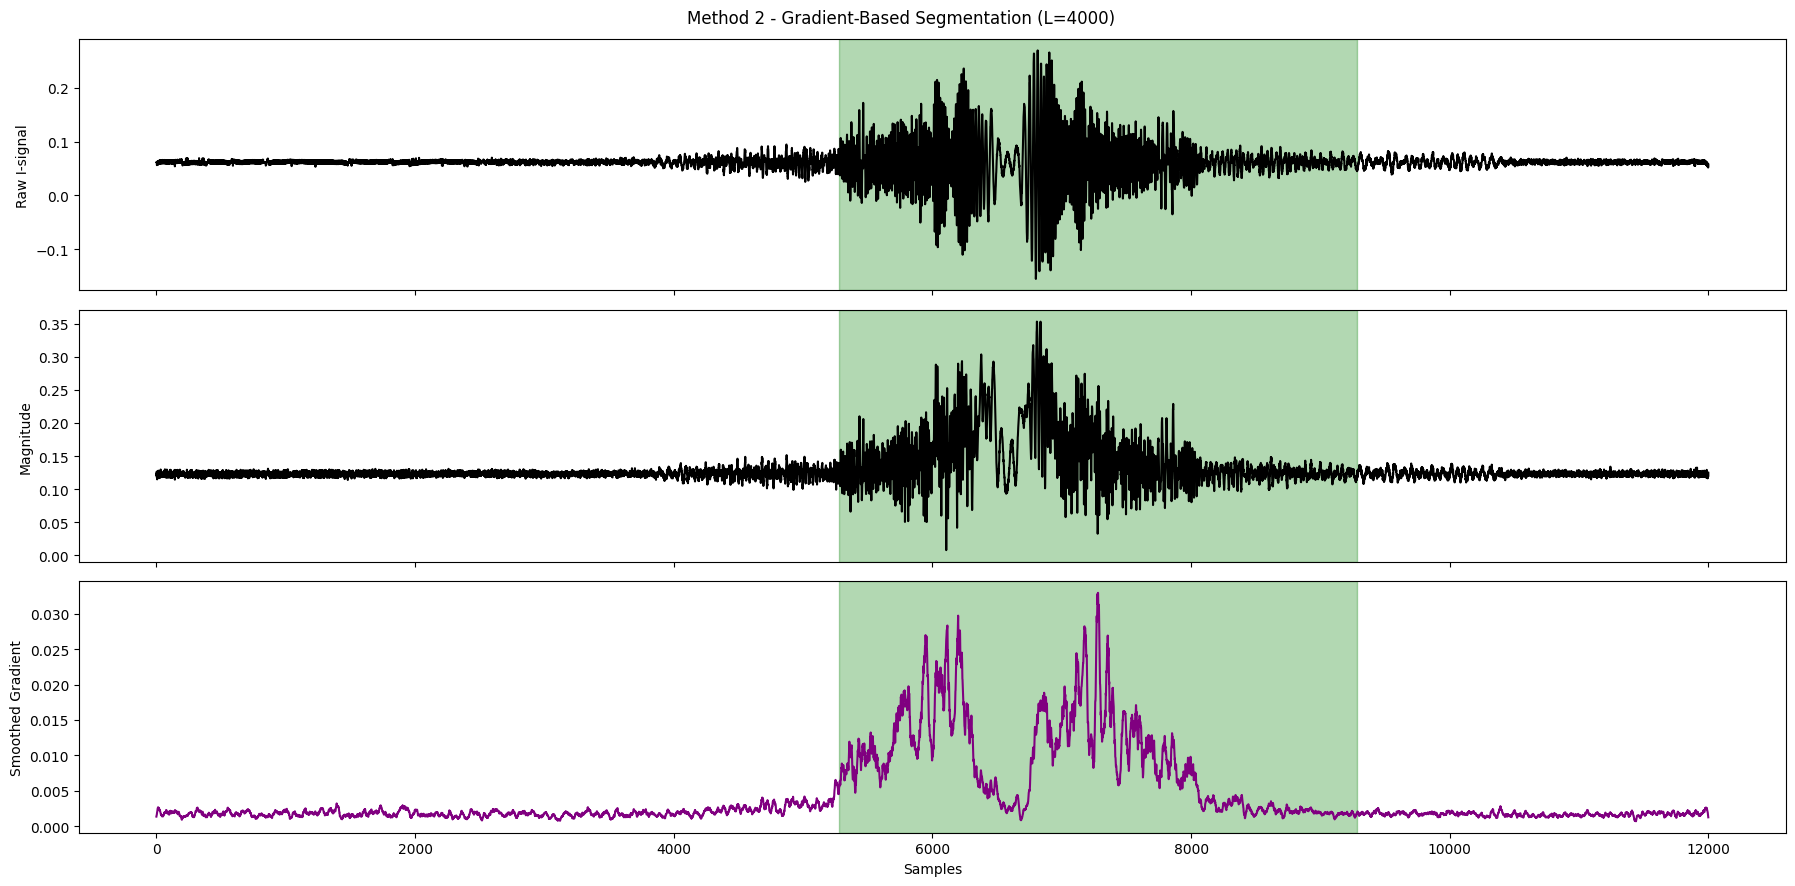

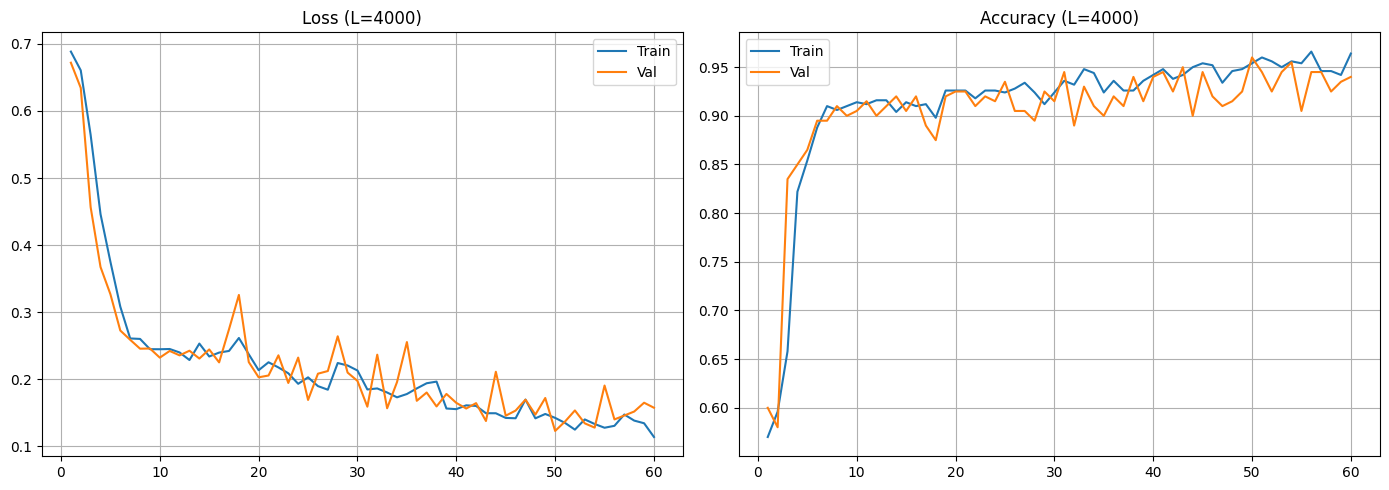

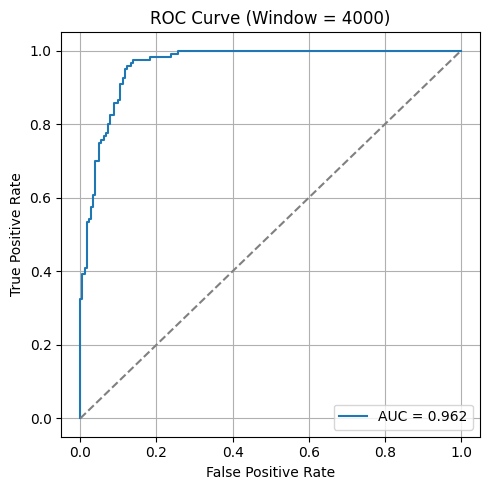

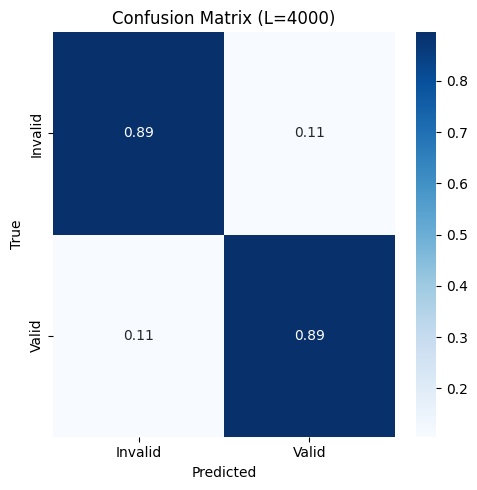


=== METHOD 2 | WINDOW = 2000 ===


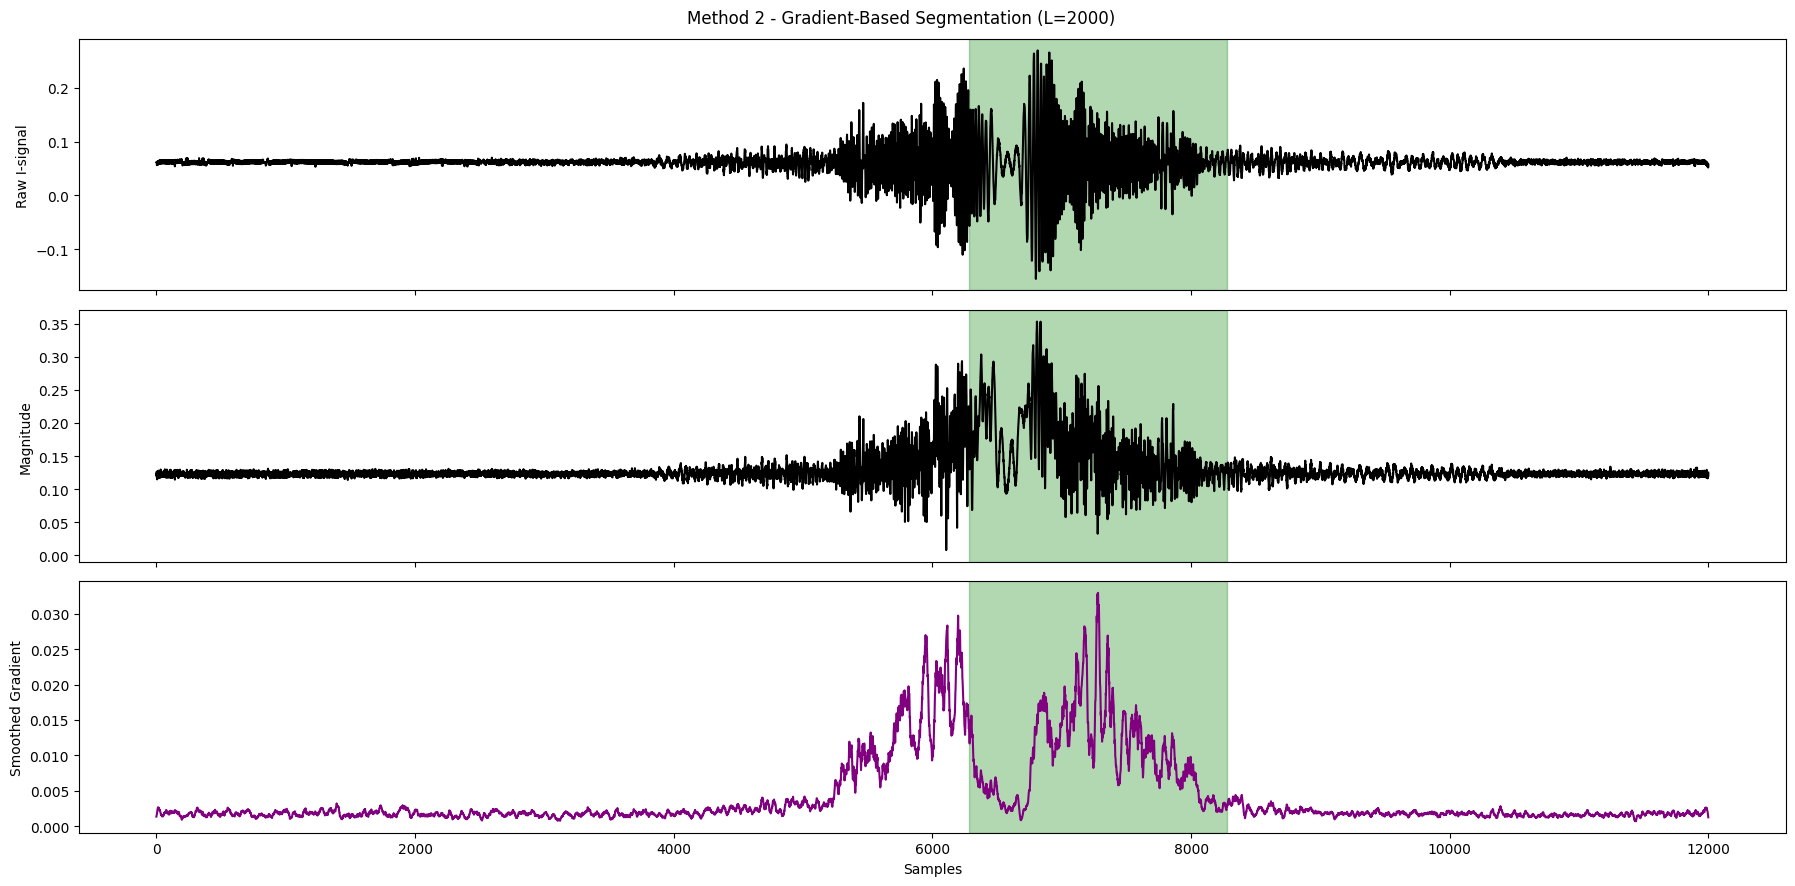

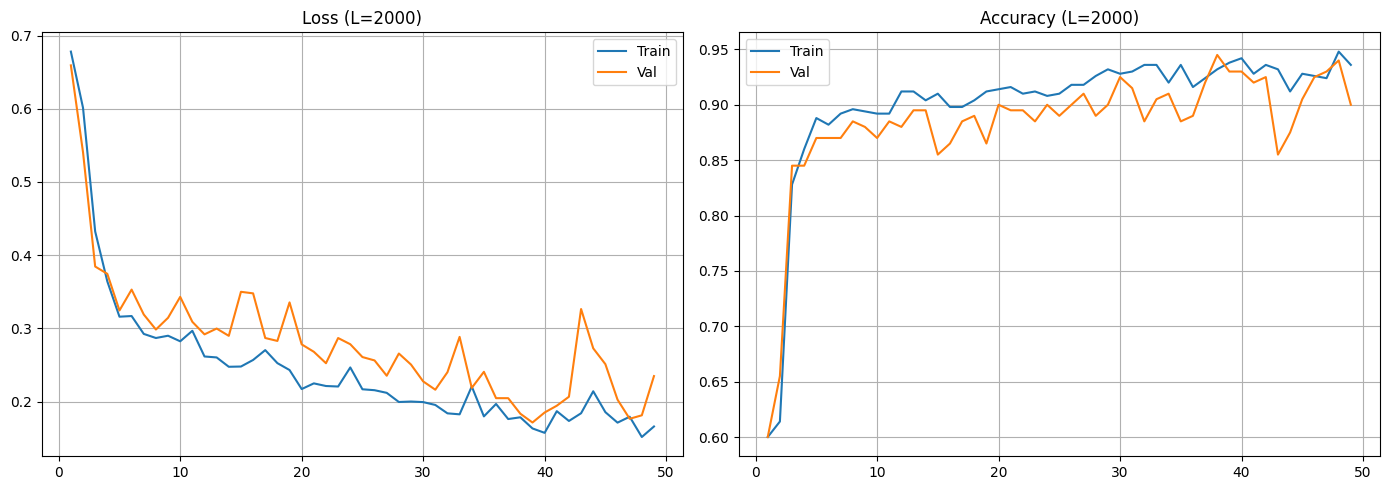

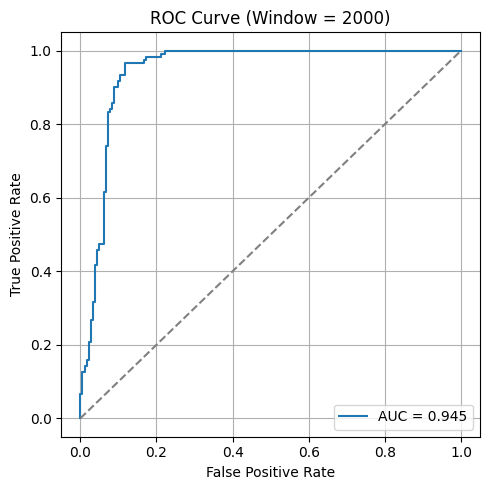

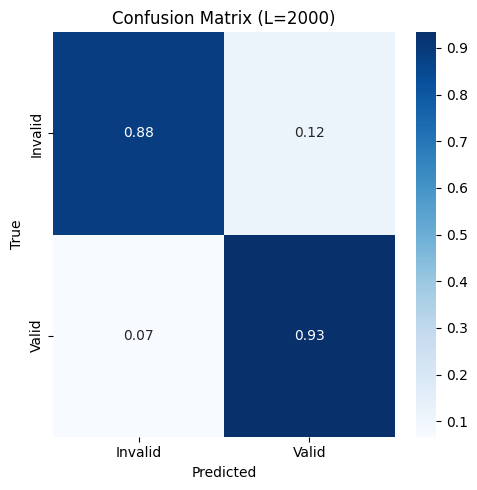


=== METHOD 2 | WINDOW = 1000 ===


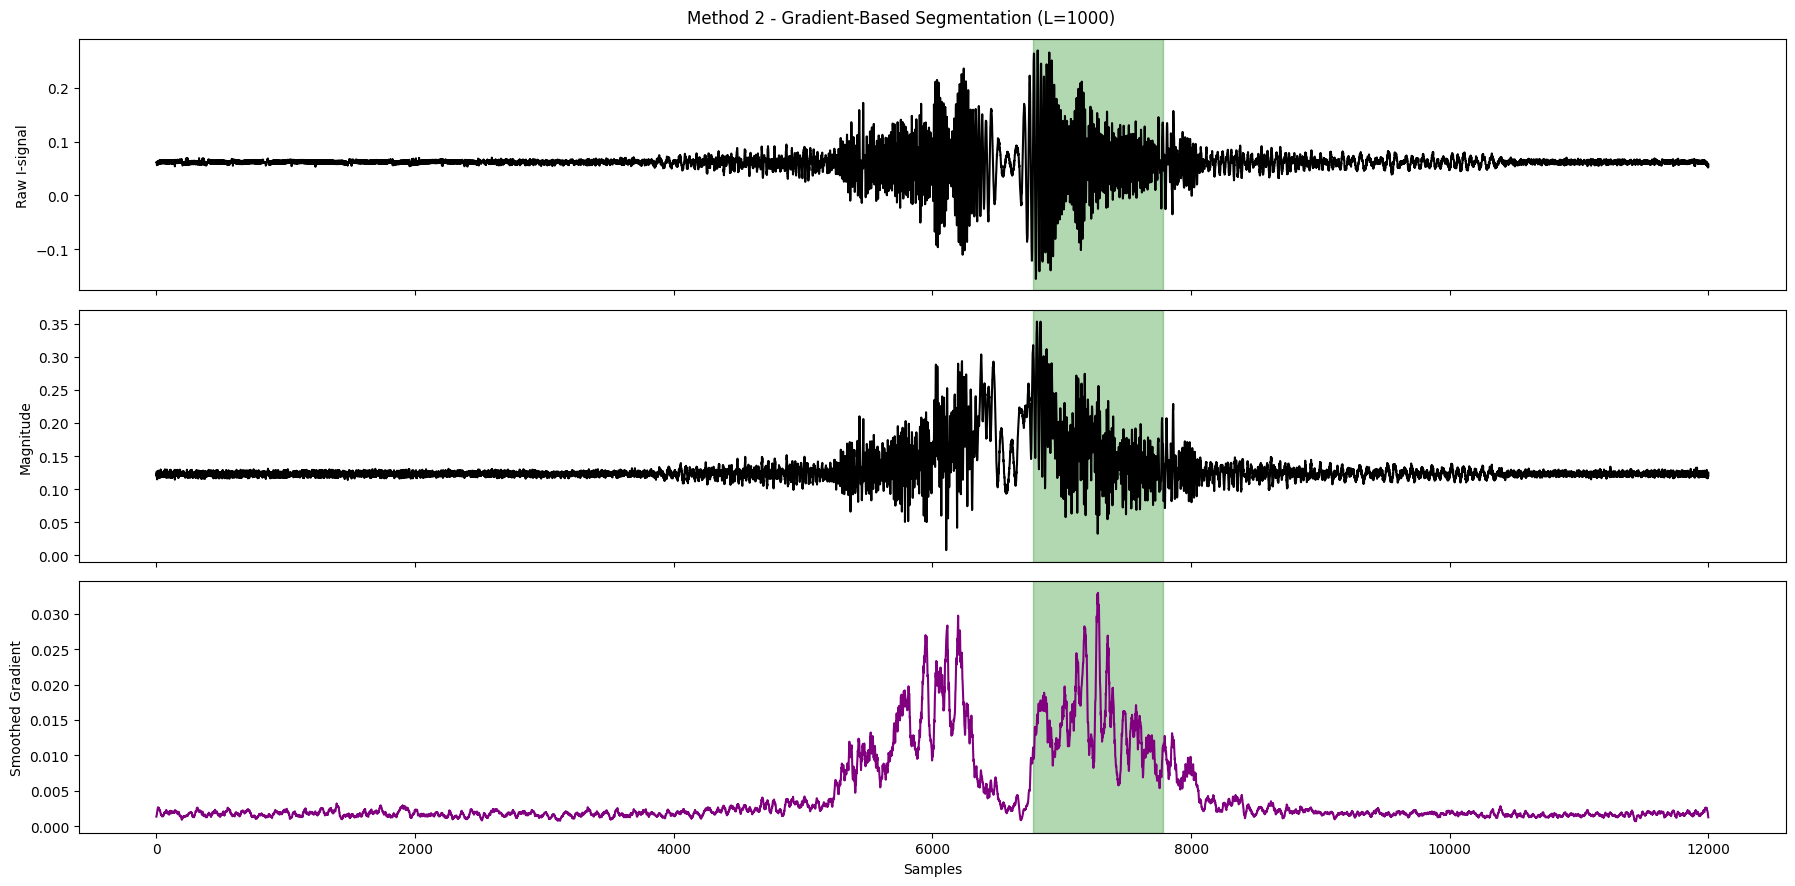

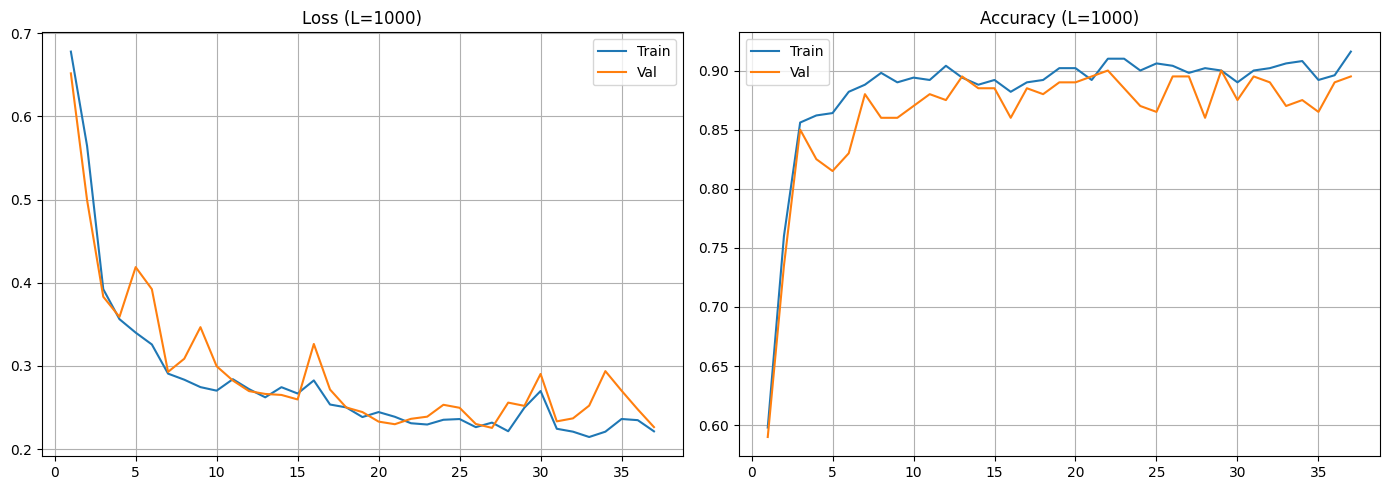

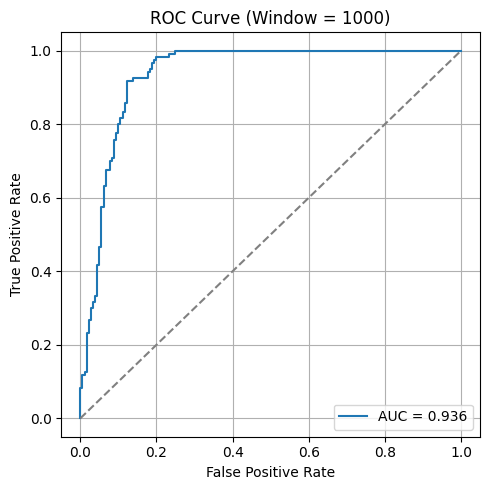

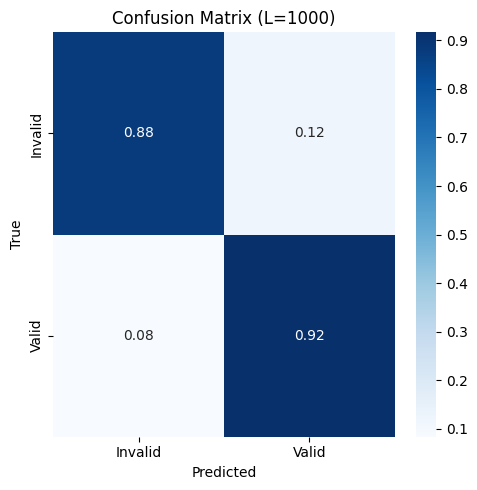


=== METHOD-2 FINAL TABLE [GRADIENT BASED METHOD] ===


,Window,ACC,Precision,Recall_TPR,FPR,AUC
0,4000,0.8933,0.8492,0.8917,0.1056,0.9619
1,2000,0.9033,0.8421,0.9333,0.1167,0.9451
2,1000,0.8933,0.8333,0.9167,0.1222,0.9356


In [ ]:
# ============================================================
# METHOD 2 – GRADIENT PEAK SEGMENTATION
# ============================================================

# ------------------------------------------------------------
# CNN MODEL
# ------------------------------------------------------------
def make_cnn(L):
    inp = layers.Input(shape=(L, 4))

    x = layers.Conv1D(32, 7, padding="same", activation="relu")(inp)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dense(64, activation="relu")(x)

    out = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inp, out)
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model
# ------------------------------------------------------------
# FIXED 12000-SAMPLE WINDOW EXTRACTION
# ------------------------------------------------------------
def extract_12000_window(X, target_len=12000):
    """
    Enforces a fixed 12000-sample parent window.
    If signal is longer → center crop
    If shorter → discard
    """
    if len(X) < target_len:
        return None

    start = (len(X) - target_len) // 2
    end = start + target_len
    return X[start:end]

# ------------------------------------------------------------
# GRADIENT PEAK SEGMENTATION
# ------------------------------------------------------------
def segment_gradient_peak(X, L, smooth=25):
    mag = np.sqrt(np.sum(X**2, axis=1))

    # Gradient of magnitude
    grad = np.abs(np.gradient(mag))

    # Smooth gradient (moving average)
    grad_s = np.convolve(grad, np.ones(smooth)/smooth, mode="same")

    peak = np.argmax(grad_s)

    start = max(0, peak - L//2)
    end = start + L
    if end > len(X):
        end = len(X)
        start = end - L

    return X[start:end], mag, grad_s, start, end
# ------------------------------------------------------------
# SLIDING WINDOW EVALUATION (TEST ONLY)
# ------------------------------------------------------------
def sliding_window_predict(model, X_12000, L, step=500):
    """
    Sliding-window prediction over unseen test samples.
    Returns mean probability across windows.
    """
    probs = []

    for start in range(0, len(X_12000) - L + 1, step):
        window = X_12000[start:start + L]
        window = window[np.newaxis, ...]
        probs.append(model.predict(window, verbose=0)[0, 0])

    return np.mean(probs)

# ------------------------------------------------------------
# DATASET BUILDER (SEGMENT LEVEL)
# ------------------------------------------------------------
def build_dataset(df, L):
    Xs, ys, persons = [], [], []

    le = LabelEncoder()
    le.fit(df.groupby("Combination")["Binary_label"].first())

    for _, g in df.groupby("Combination"):
        X_full = g[NORM_COLS].values
        X_12000 = extract_12000_window(X_full) 

        if X_12000 is None:
            continue

        y = le.transform([g["Binary_label"].iloc[0]])[0]
        p = g["Person"].iloc[0]

        seg = segment_energy_peak(X_12000, L)    # segmentation INSIDE 12000
        if seg.shape[0] == L:
            Xs.append(seg)
            ys.append(y)
            persons.append(p)

    return np.array(Xs), np.array(ys), np.array(persons)

# ------------------------------------------------------------
# VISUALIZATION (RAW + MAG + GRADIENT)
# ------------------------------------------------------------
def plot_gradient_segmentation(df, L):
    g = next(iter(df.groupby("Combination")))[1]
    X_full = g[NORM_COLS].values
    raw = g["I_data_upper_bp_norm"].values

    _, mag, grad_s, start, end = segment_gradient_peak(X_full, L)

    fig, ax = plt.subplots(3, 1, figsize=(18, 9), sharex=True)

    ax[0].plot(raw, color="black")
    ax[0].axvspan(start, end, color="green", alpha=0.3)
    ax[0].set_ylabel("Raw I-signal")

    ax[1].plot(mag, color="black")
    ax[1].axvspan(start, end, color="green", alpha=0.3)
    ax[1].set_ylabel("Magnitude")

    ax[2].plot(grad_s, color="purple")
    ax[2].axvspan(start, end, color="green", alpha=0.3)
    ax[2].set_ylabel("Smoothed Gradient")
    ax[2].set_xlabel("Samples")

    plt.suptitle(f"Method 2 - Gradient-Based Segmentation (L={L})")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# TRAINING CURVES
# ------------------------------------------------------------
def plot_training_curves(history, L):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)

    plt.figure(figsize=(14,5))

    plt.subplot(1,2,1)
    plt.plot(epochs, h["loss"], label="Train")
    plt.plot(epochs, h["val_loss"], label="Val")
    plt.title(f"Loss (L={L})")
    plt.grid(True)
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs, h["accuracy"], label="Train")
    plt.plot(epochs, h["val_accuracy"], label="Val")
    plt.title(f"Accuracy (L={L})")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# ROC CURVE (Plot)
# ------------------------------------------------------------
def plot_roc_curve(y_test, y_prob, window_size):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = auc(fpr, tpr)

    plt.figure(figsize=(5, 5))
    plt.plot(fpr, tpr, label=f'AUC = {auc_value:.3f}')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'ROC Curve (Window = {window_size})')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
# ------------------------------------------------------------
# MAIN PIPELINE
# ------------------------------------------------------------
results = []

for L in WINDOWS:
    print(f"\n=== METHOD 2 | WINDOW = {L} ===")

    X, y, persons = build_dataset(normalized_df, L)

    plot_gradient_segmentation(normalized_df, L)

    test_mask = np.isin(persons, TEST_PERSONS)
    X_trainval, y_trainval = X[~test_mask], y[~test_mask]
    X_test, y_test = X[test_mask], y[test_mask]
    persons_trainval = persons[~test_mask]

    gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    tr_idx, val_idx = next(gss.split(X_trainval, y_trainval, groups=persons_trainval))

    model = make_cnn(L)
    

    es = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = model.fit(
        X_trainval[tr_idx], y_trainval[tr_idx],
        validation_data=(X_trainval[val_idx], y_trainval[val_idx]),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[es],
        verbose=0
    )
    # Plot curves
    plot_training_curves(history, L)

    # ------------------------------------------------------------
    # SLIDING-WINDOW TEST EVALUATION (UNSEEN PERSONS)
    # ------------------------------------------------------------
    y_prob, y_pred = [], []

    for i in range(len(X_test)):
        prob = sliding_window_predict(model, X_test[i], L)
        y_prob.append(prob)
        y_pred.append(int(prob >= 0.5))

    y_prob = np.array(y_prob)
    y_pred = np.array(y_pred)

    
    # ROC curve 
    plot_roc_curve(y_test, y_prob, L)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    results.append({
        "Window": L,
        "ACC": (tp+tn)/(tp+tn+fp+fn),
        "Precision": precision_score(y_test, y_pred),
        "Recall_TPR": recall_score(y_test, y_pred),
        "FPR": fp/(fp+tn),
        "AUC": auc(*roc_curve(y_test, y_prob)[:2])
    })

    cm = confusion_matrix(y_test, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(5,5))
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=["Invalid","Valid"],
                yticklabels=["Invalid","Valid"])
    plt.title(f"Confusion Matrix (L={L})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# FINAL TABLE
# ------------------------------------------------------------
m2_table = pd.DataFrame(results).sort_values("Window", ascending=False)

print("\n=== METHOD-2 FINAL TABLE [GRADIENT BASED METHOD] ===")
display(m2_table.round(4))



=== METHOD 3 | WINDOW = 4000 ===


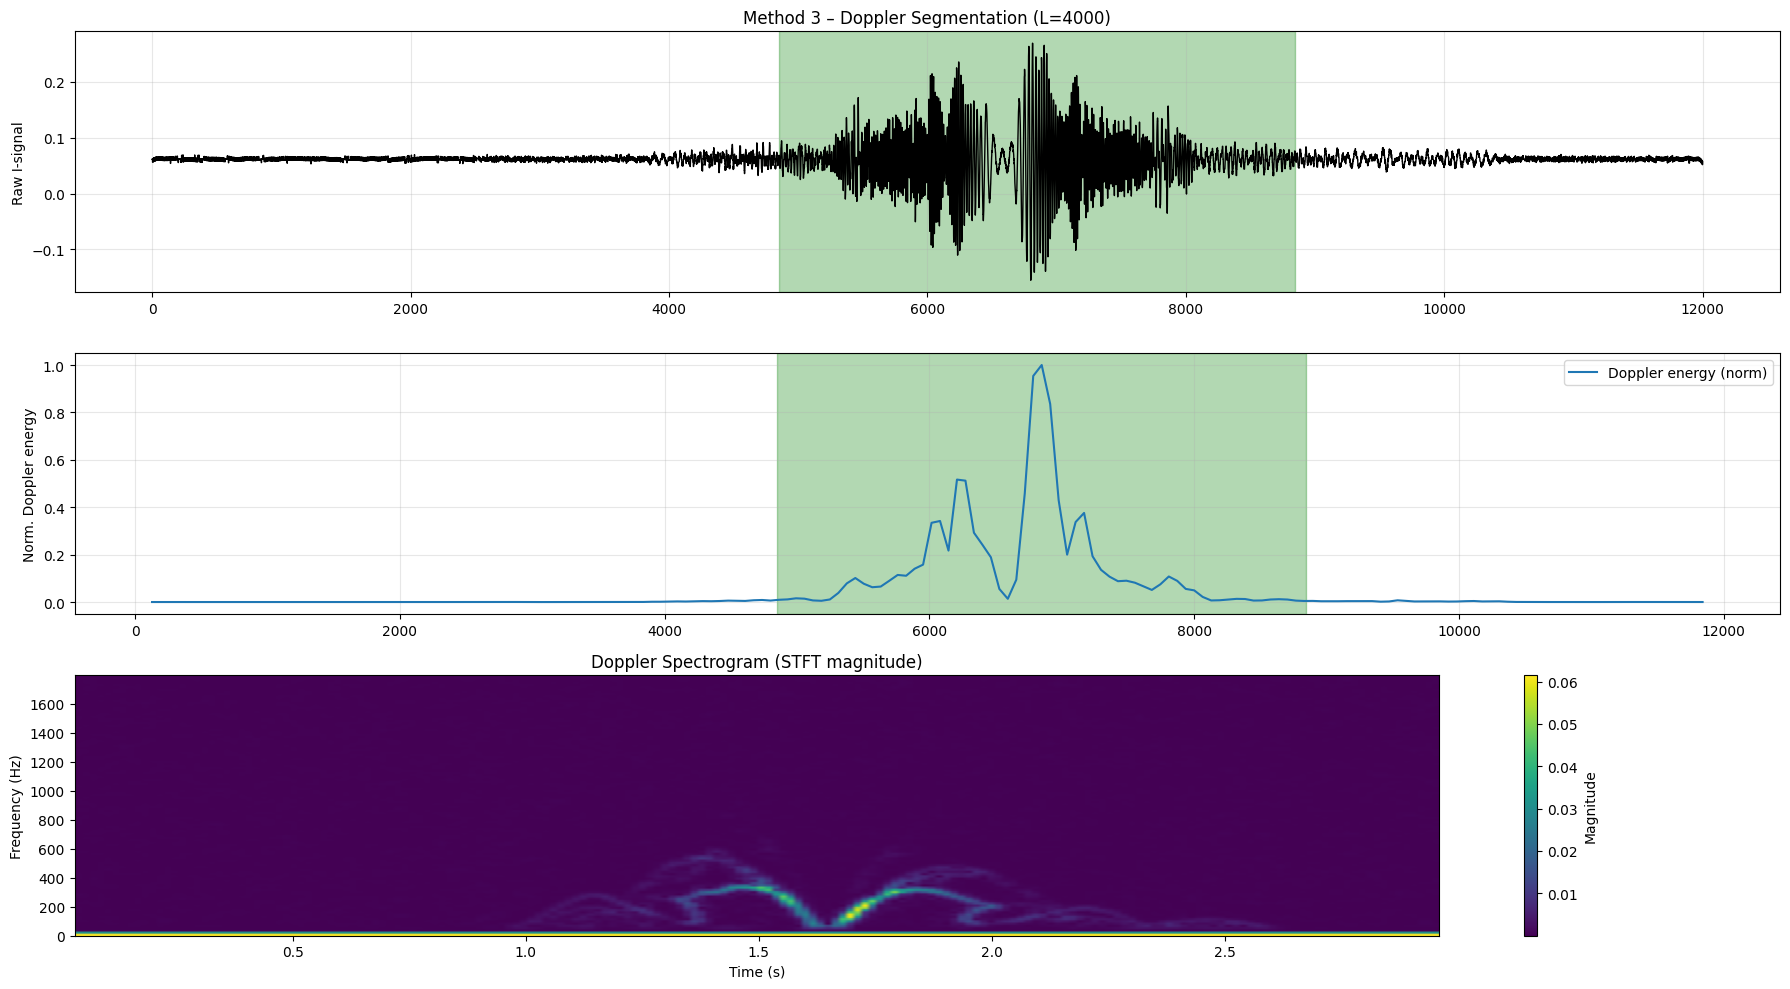

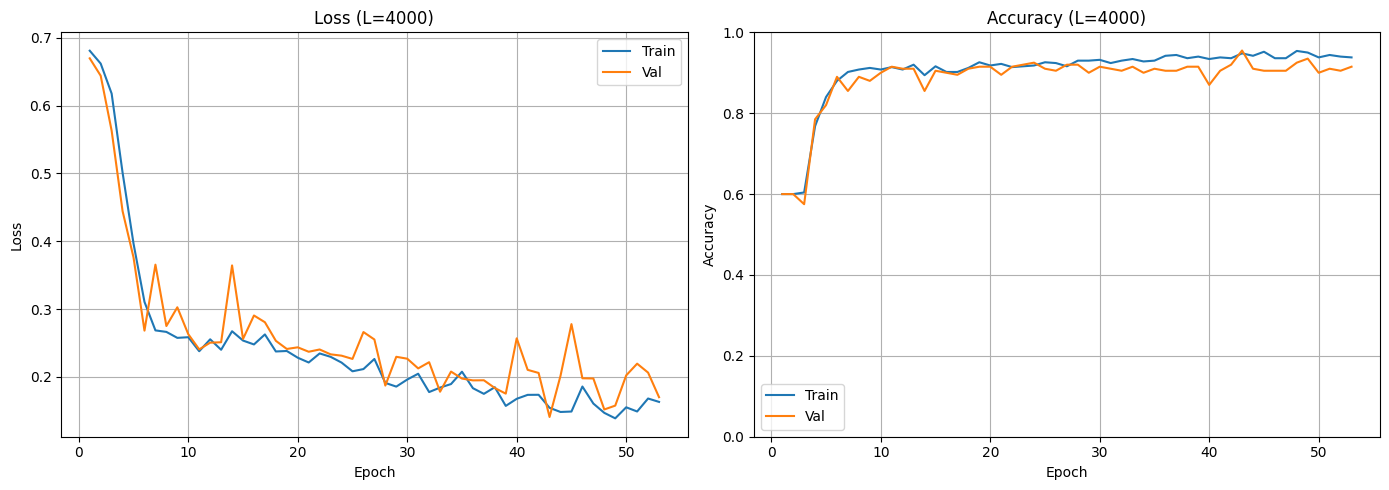

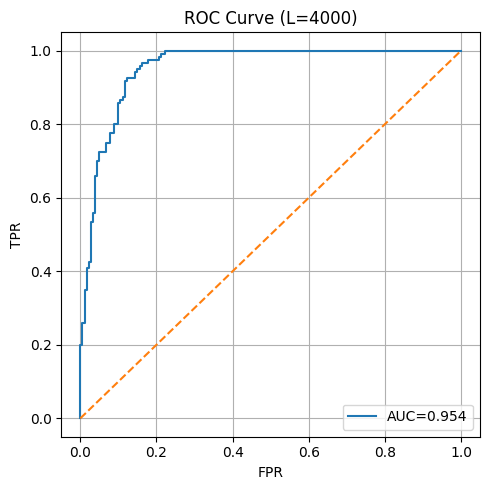

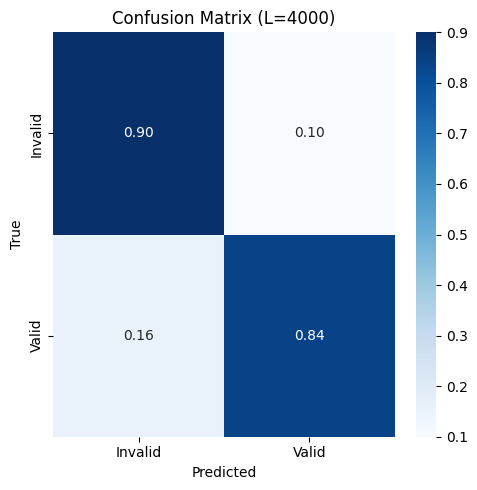


=== METHOD 3 | WINDOW = 2000 ===


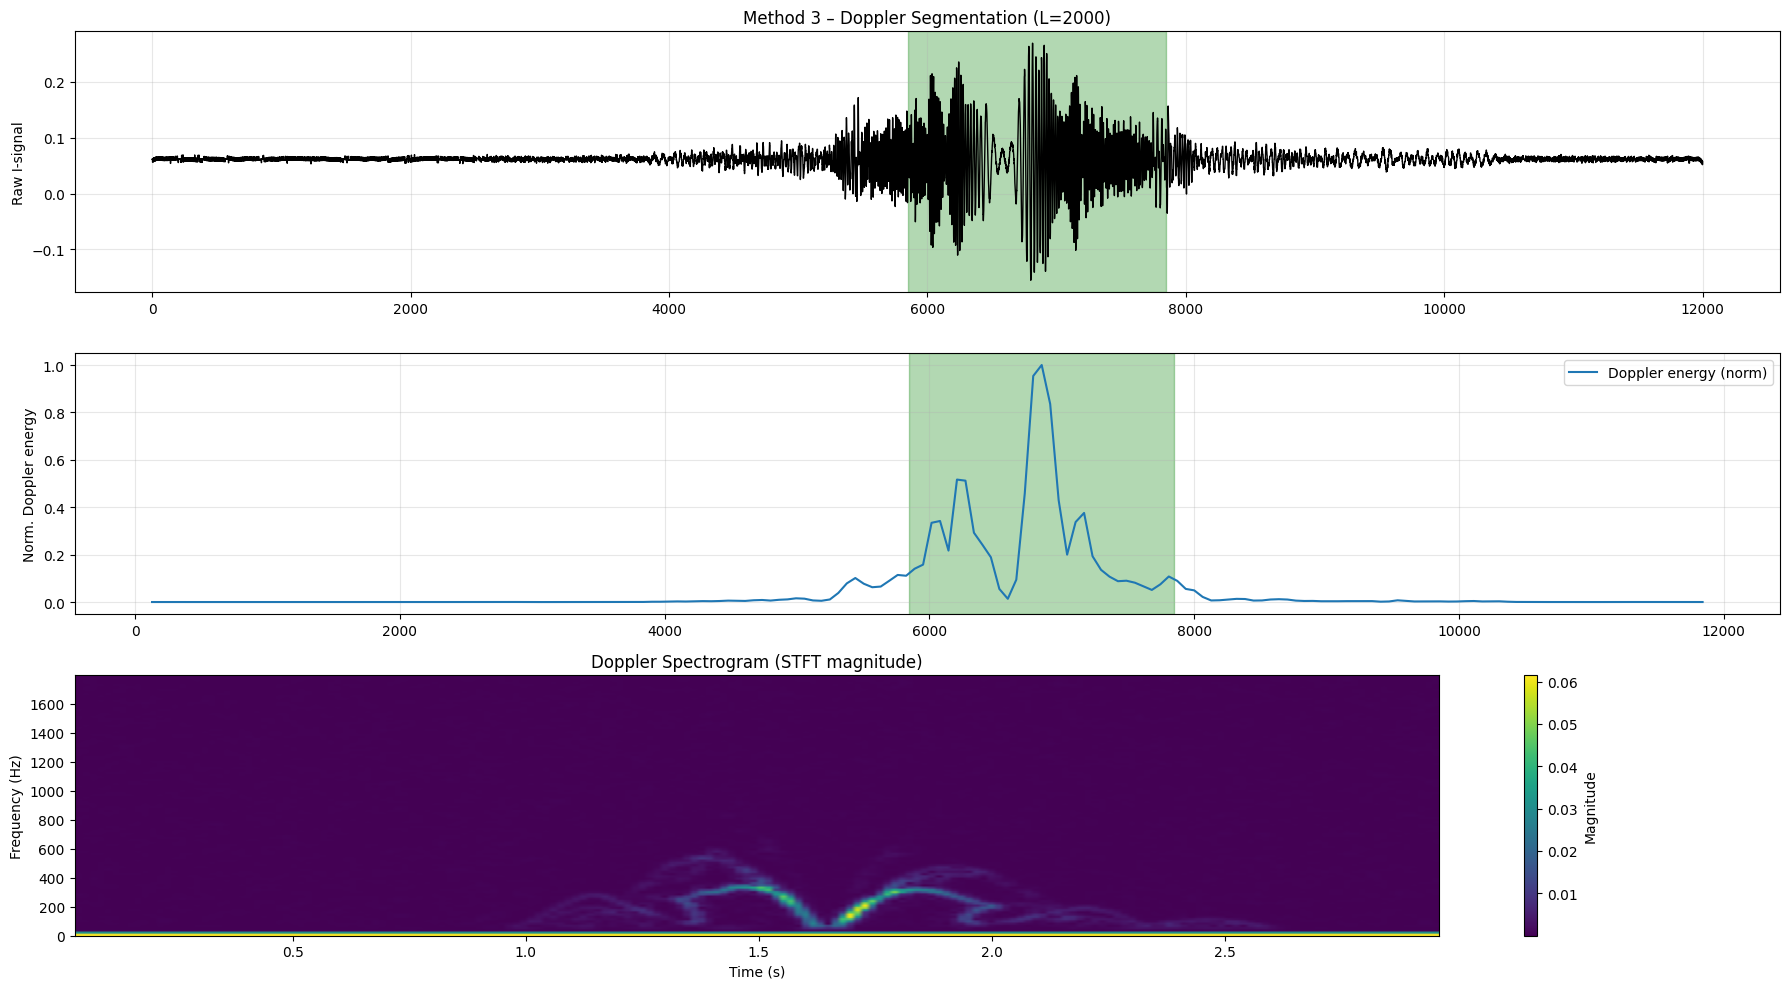

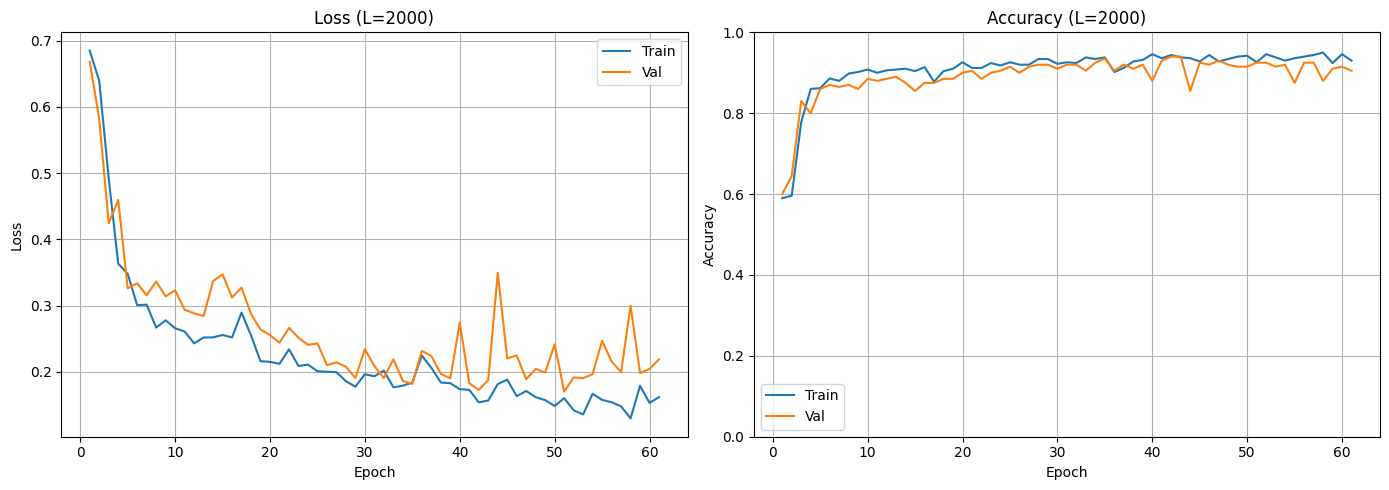

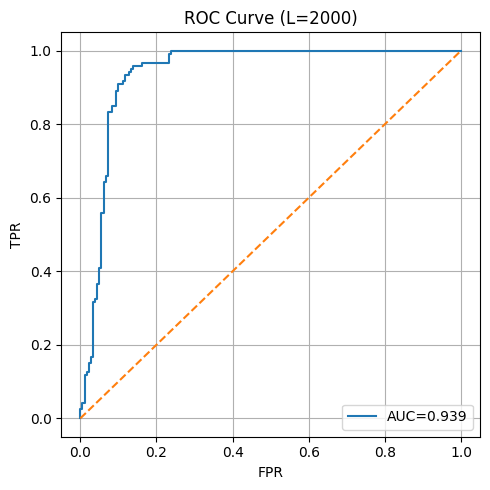

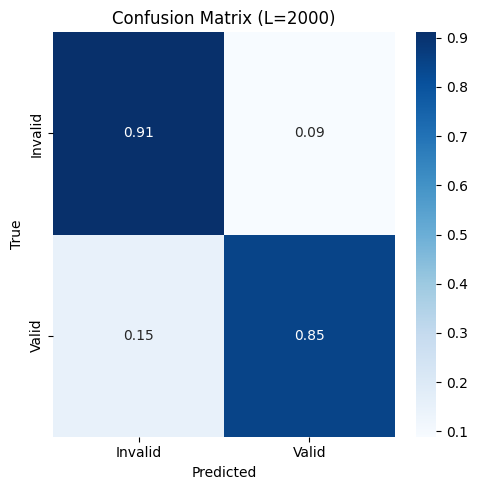


=== METHOD 3 | WINDOW = 1000 ===


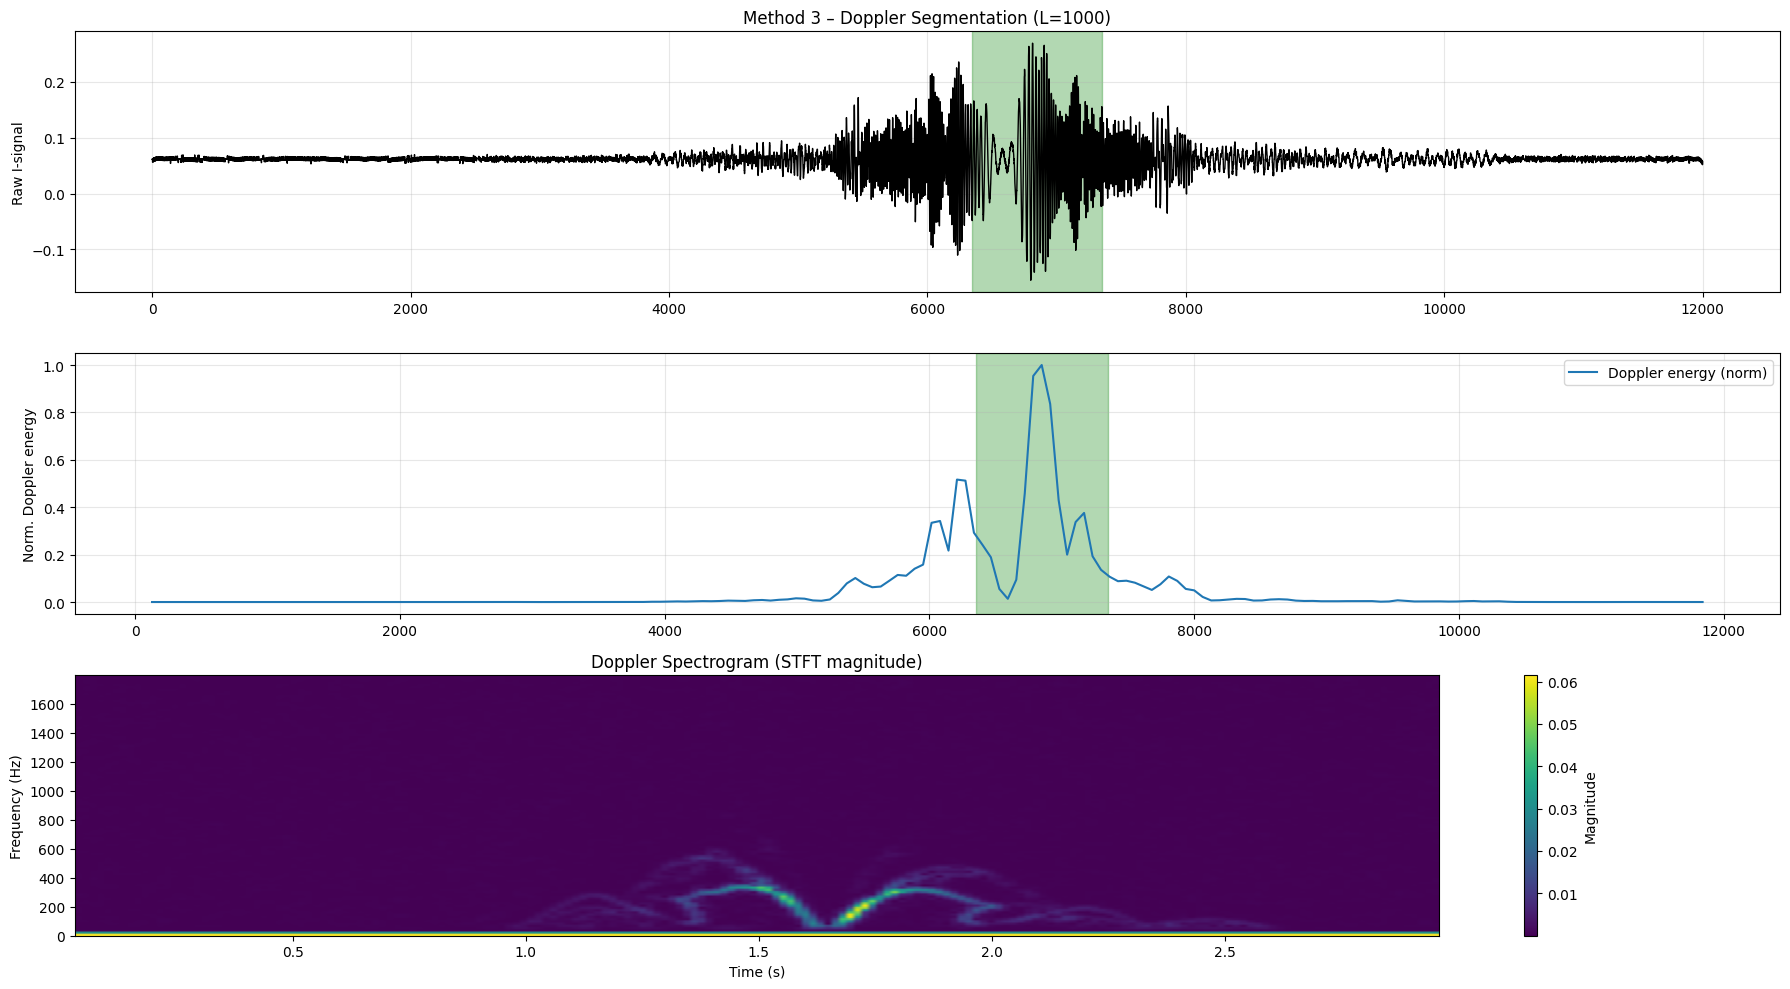

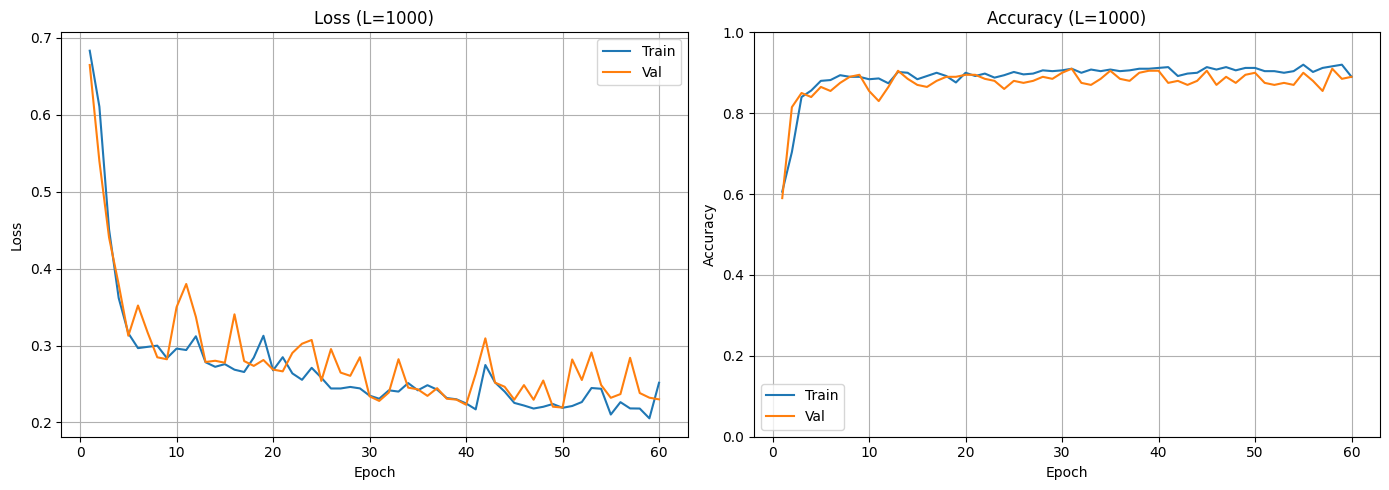

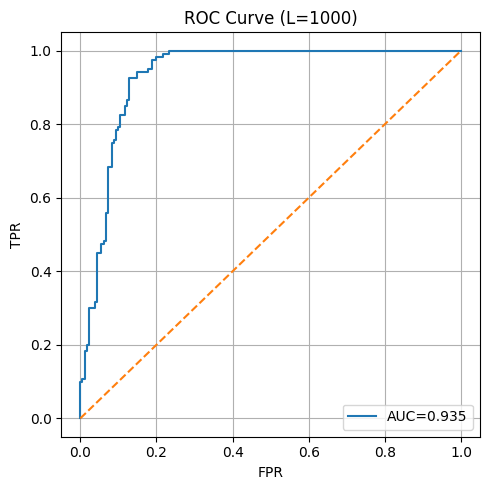

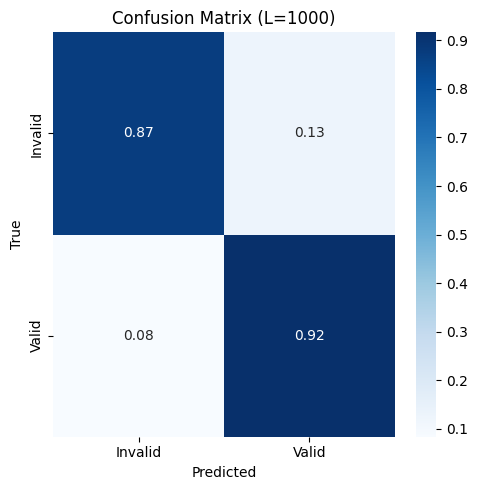


=== METHOD-3 FINAL TABLE (Doppler segmentation) ===


,Window,ACC,Precision,Recall_TPR,FPR,AUC
0,4000,0.8767,0.8487,0.8417,0.1000,0.9540
1,2000,0.8867,0.8644,0.8500,0.0889,0.9391
2,1000,0.8900,0.8271,0.9167,0.1278,0.9346


In [ ]:
# ============================================================
# METHOD 3 – DOPPLER (STFT) PEAK SEGMENTATION
# ============================================================

# CONFIGURATION
# STFT params
FS = 4000
NFFT = 256
NOVERLAP = 192
FMAX_HZ = 1800         # limit doppler band for "doppler energy" computation

# ------------------------------------------------------------
# CNN MODEL
# ------------------------------------------------------------
def make_cnn(L):
    inp = layers.Input(shape=(L, 4))

    x = layers.Conv1D(32, 7, padding="same", activation="relu")(inp)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dense(64, activation="relu")(x)

    out = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inp, out)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model
# ------------------------------------------------------------
# FIXED 12000-SAMPLE WINDOW EXTRACTION 
# ------------------------------------------------------------
def extract_12000_window(X, target_len=12000):
    """
    Enforces a fixed 12000-sample parent window.
    If signal is longer → center crop
    If shorter → discard
    """
    if len(X) < target_len:
        return None

    start = (len(X) - target_len) // 2
    end = start + target_len
    return X[start:end]

# ------------------------------------------------------------
# Doppler segmentation helpers
# ------------------------------------------------------------
def _doppler_energy_curve(raw_signal, fs=FS, nfft=NFFT, noverlap=NOVERLAP, fmax=FMAX_HZ):
    """
    Returns:
      t_frames_sec: time axis for STFT frames (seconds)
      doppler_energy_norm: normalized doppler energy per frame in [0,1]
      f, t, Zxx: STFT outputs (for spectrogram plot)
    """
    f, t, Zxx = stft(raw_signal, fs=fs, nperseg=nfft, noverlap=noverlap, padded=False, boundary=None)

    # magnitude spectrogram
    S = np.abs(Zxx)

    # keep frequency band (both +/- freqs appear depending on stft impl; scipy gives 0..fs/2)
    fmask = (f <= fmax)
    S_band = S[fmask, :]

    # Doppler energy per frame
    e = np.sum(S_band**2, axis=0)

    # normalize to [0,1] for thresholding/peak detection
    if np.max(e) > 0:
        e_norm = (e - np.min(e)) / (np.max(e) - np.min(e) + 1e-12)
    else:
        e_norm = e.copy()

    return t, e_norm, f, t, S

def _frames_to_samples(frame_idx, total_samples, fs=FS, nfft=NFFT, noverlap=NOVERLAP):
    """
    Map STFT frame index -> approximate sample index in original signal.
    For scipy.stft: hop length = nperseg - noverlap
    """
    hop = nfft - noverlap
    center_sample = int(frame_idx * hop + nfft // 2)
    return int(np.clip(center_sample, 0, total_samples - 1))


def segment_doppler_peak(X, L, fs=FS, nfft=NFFT, noverlap=NOVERLAP, fmax=FMAX_HZ):
    """
    Doppler-based segmentation:
    - Use one raw channel (I_data_upper_bp_norm) to compute STFT
    - Compute doppler-energy curve across time frames
    - Take peak frame -> map to sample index -> center window [start:end]
    Returns:
      seg, raw, t_frames, e_norm, start, end, (f, t, S) for plots
    """
    # choose a raw channel for doppler (you can switch to magnitude too)
    raw = X[:, 2]  # I_data_upper_bp_norm if NORM_COLS order matches

    t_frames, e_norm, f, t_spec, S = _doppler_energy_curve(raw, fs, nfft, noverlap, fmax)
    peak_frame = int(np.argmax(e_norm))
    peak_sample = _frames_to_samples(peak_frame, len(raw), fs, nfft, noverlap)

    start = max(0, peak_sample - L // 2)
    end = start + L
    if end > len(raw):
        end = len(raw)
        start = end - L

    seg = X[start:end]
    return seg, raw, t_frames, e_norm, start, end, (f, t_spec, S)

# ------------------------------------------------------------
# SLIDING WINDOW EVALUATION (TEST ONLY)
# ------------------------------------------------------------
def sliding_window_predict(model, X_12000, L, step=500):
    """
    Sliding-window prediction over unseen test samples.
    Returns mean probability across windows.
    """
    probs = []

    for start in range(0, len(X_12000) - L + 1, step):
        window = X_12000[start:start + L]
        window = window[np.newaxis, ...]
        probs.append(model.predict(window, verbose=0)[0, 0])

    return np.mean(probs)

# ------------------------------------------------------------
# DATASET BUILDER (segment level)
# ------------------------------------------------------------
def build_dataset(df, L):
    Xs, ys, persons = [], [], []

    le = LabelEncoder()
    le.fit(df.groupby("Combination")["Binary_label"].first())

    for _, g in df.groupby("Combination"):
        X_full = g[NORM_COLS].values
        X_12000 = extract_12000_window(X_full) 

        if X_12000 is None:
            continue

        y = le.transform([g["Binary_label"].iloc[0]])[0]
        p = g["Person"].iloc[0]

        seg = segment_energy_peak(X_12000, L)    # segmentation INSIDE 12000
        if seg.shape[0] == L:
            Xs.append(seg)
            ys.append(y)
            persons.append(p)

    return np.array(Xs), np.array(ys), np.array(persons)

# ------------------------------------------------------------
# VISUALIZATION (Raw + Doppler energy + Spectrogram)
# ------------------------------------------------------------
def plot_doppler_segmentation(df, L):
    # take first sequence for visualization
    g = next(iter(df.groupby("Combination")))[1]
    X_full = g[NORM_COLS].values.astype(np.float32)

    seg, raw, t_frames, e_norm, start, end, (f, t_spec, S) = segment_doppler_peak(X_full, L)

    # Map t_frames (sec) to sample index for plotting energy curve vs samples
    # Create an x-axis in samples for each frame based on hop mapping
    hop = NFFT - NOVERLAP
    frame_sample_x = np.clip((np.arange(len(e_norm)) * hop + NFFT//2).astype(int), 0, len(raw)-1)

    fig, ax = plt.subplots(3, 1, figsize=(18, 10))

    # 1) raw signal
    ax[0].plot(raw, color="black", linewidth=1)
    ax[0].axvspan(start, end, color="green", alpha=0.3)
    ax[0].set_title(f"Method 3 – Doppler Segmentation (L={L})")
    ax[0].set_ylabel("Raw I-signal")
    ax[0].grid(True, alpha=0.3)

    # 2) doppler energy curve
    ax[1].plot(frame_sample_x, e_norm, color="tab:blue", linewidth=1.5, label="Doppler energy (norm)")
    ax[1].axvspan(start, end, color="green", alpha=0.3)
    ax[1].set_ylabel("Norm. Doppler energy")
    ax[1].grid(True, alpha=0.3)
    ax[1].legend(loc="upper right")

    # 3) spectrogram (STFT magnitude)
    # Use only up to FMAX_HZ for view (0..FMAX_HZ)
    fmask = (f <= FMAX_HZ)
    Sview = np.abs(S)[fmask, :]
    extent = [t_spec[0], t_spec[-1], f[fmask][0], f[fmask][-1]]
    im = ax[2].imshow(Sview, aspect="auto", origin="lower", extent=extent)
    ax[2].set_title("Doppler Spectrogram (STFT magnitude)")
    ax[2].set_xlabel("Time (s)")
    ax[2].set_ylabel("Frequency (Hz)")
    plt.colorbar(im, ax=ax[2], label="Magnitude")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# TRAINING CURVES (loss & accuracy)
# ------------------------------------------------------------
def plot_training_curves(history, L):
    h = history.history
    epochs = np.arange(1, len(h["loss"]) + 1)

    plt.figure(figsize=(14,5))

    plt.subplot(1,2,1)
    plt.plot(epochs, h["loss"], label="Train")
    plt.plot(epochs, h["val_loss"], label="Val")
    plt.title(f"Loss (L={L})")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs, h["accuracy"], label="Train")
    plt.plot(epochs, h["val_accuracy"], label="Val")
    plt.title(f"Accuracy (L={L})")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1.0)
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# MAIN PIPELINE
# ------------------------------------------------------------
results = []

for L in WINDOWS:
    print(f"\n=== METHOD 3 | WINDOW = {L} ===")

    # build dataset
    X, y, persons = build_dataset(normalized_df, L)

    # segmentation visualization
    plot_doppler_segmentation(normalized_df, L)

    # fixed person-wise split
    test_mask = np.isin(persons, TEST_PERSONS)
    X_trainval, y_trainval = X[~test_mask], y[~test_mask]
    X_test, y_test = X[test_mask], y[test_mask]
    persons_trainval = persons[~test_mask]

    # inner split (train/val)
    gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    tr_idx, val_idx = next(gss.split(X_trainval, y_trainval, groups=persons_trainval))

    model = make_cnn(L)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)

    history = model.fit(
        X_trainval[tr_idx], y_trainval[tr_idx],
        validation_data=(X_trainval[val_idx], y_trainval[val_idx]),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[es],
        verbose=0
    )

    # loss/accuracy curves
    plot_training_curves(history, L)

    # ------------------------------------------------------------
    # SLIDING-WINDOW TEST EVALUATION (UNSEEN PERSONS)
    # ------------------------------------------------------------
    y_prob, y_pred = [], []

    for i in range(len(X_test)):
        prob = sliding_window_predict(model, X_test[i], L)
        y_prob.append(prob)
        y_pred.append(int(prob >= 0.5))

    y_prob = np.array(y_prob)
    y_pred = np.array(y_pred)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    fpr_curve, tpr_curve, _ = roc_curve(y_test, y_prob)

    results.append({
        "Window": L,
        "ACC": (tp + tn) / (tp + tn + fp + fn + 1e-12),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall_TPR": recall_score(y_test, y_pred, zero_division=0),
        "FPR": fp / (fp + tn + 1e-12),
        "AUC": auc(fpr_curve, tpr_curve)
    })

    # ROC curve
    plt.figure(figsize=(5,5))
    plt.plot(fpr_curve, tpr_curve, label=f"AUC={auc(fpr_curve, tpr_curve):.3f}")
    plt.plot([0,1], [0,1], "--")
    plt.title(f"ROC Curve (L={L})")
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Confusion matrix (row-normalized, thesis style 0.xx)
    cm = confusion_matrix(y_test, y_pred)
    cm_norm = cm / (cm.sum(axis=1, keepdims=True) + 1e-12)

    plt.figure(figsize=(5,5))
    sns.heatmap(
        cm_norm, annot=True, fmt=".2f", cmap="Blues",
        xticklabels=["Invalid", "Valid"],
        yticklabels=["Invalid", "Valid"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix (L={L})")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# FINAL TABLE 
# ------------------------------------------------------------
m3_table = pd.DataFrame(results).sort_values("Window", ascending=False)

print("\n=== METHOD-3 FINAL TABLE (Doppler segmentation) ===")
display(m3_table.round(4))


In [52]:
# ------------------------------------------------------------
# COMBINE ALL METHODS IN FINAL COMPARISON TABLE
# ------------------------------------------------------------

def tag_method(df, method_name):
    df = df.copy()
    df["Method"] = method_name
    return df

m1 = tag_method(m1_table, "Method 1 - Energy Peak")
m2 = tag_method(m2_table, "Method 2 - Gradient")
m3 = tag_method(m3_table, "Method 3 - Doppler")

comparison_table = pd.concat([m1, m2, m3], ignore_index=True)

# Reorder columns (thesis style)
comparison_table = comparison_table[
    ["Method", "Window", "ACC", "Precision", "Recall_TPR", "FPR", "AUC"]
]

# Sort for readability
comparison_table = comparison_table.sort_values(
    by=["Method", "Window"],
    ascending=[True, False]
)

print("\n=== FINAL COMPARISON TABLE ===")
display(comparison_table.round(4))



=== FINAL COMPARISON TABLE ===


,Method,Window,ACC,Precision,Recall_TPR,FPR,AUC
0,Method 1 - Energy Peak,4000,0.8967,0.8397,0.9167,0.1167,0.9548
1,Method 1 - Energy Peak,2000,0.8933,0.8548,0.8833,0.1000,0.9432
2,Method 1 - Energy Peak,1000,0.8867,0.8308,0.9000,0.1222,0.9283
3,Method 2 - Gradient,4000,0.8933,0.8492,0.8917,0.1056,0.9619
4,Method 2 - Gradient,2000,0.9033,0.8421,0.9333,0.1167,0.9451
5,Method 2 - Gradient,1000,0.8933,0.8333,0.9167,0.1222,0.9356
6,Method 3 - Doppler,4000,0.8767,0.8487,0.8417,0.1000,0.9540
7,Method 3 - Doppler,2000,0.8867,0.8644,0.8500,0.0889,0.9391
8,Method 3 - Doppler,1000,0.8900,0.8271,0.9167,0.1278,0.9346
